# Plantilla reproducible del proyecto final

**Pregunta guía:** ¿Puede otra persona reconstruir y cuestionar el resultado?<br>
**Duración sugerida:** 2 horas.<br>
**Entorno:** CPU; datos incluidos o generados en memoria.

El orden de trabajo es siempre: problema → matemática → implementación
mínima → biblioteca → evaluación → interpretación física.


## Proyecto: datos y evidencia

Priorice una fuente pública con descarga reproducible y un presupuesto que permita iterar. UCI superconductividad ofrece un punto de partida físico; Fashion-MNIST y CIFAR-10 permiten comparar representaciones. Distinga datos observados, simulados y derivados. Incluya una línea base clásica y una MLP antes de justificar una arquitectura más avanzada; no se exige que lo más complejo gane.


## Identificación

- **Título:** Redes Neuronales Líquidas (LTC) para predecir un péndulo amortiguado no lineal a partir de mediciones ruidosas.
- **Integrantes:** Valentina Vega Castillo, Leidy Mariana Piñeros Garcia, Juan Jose Gonzales
- **Modelo neural no estudiado directamente en clase:** Liquid Neural Networks
- **Pregunta física y predicción falsable:** ¿puede una red con constante de tiempo dependiente del estado (LTC) reconstruir la dinámica no lineal de un péndulo amortiguado a partir de mediciones ruidosas de una sola variable (el ángulo) y seguir funcionando con amplitudes mayores que las vistas en entrenamiento? **H1:** la versión líquida (la conductancia modula la constante de tiempo) supera a la versión con τ fija en RMSE de test por más que la dispersión combinada entre semillas; si no, la "liquidez" no aporta en este sistema. **H2:** el cociente RMSE_OOD / RMSE_test de la LNN es menor que el de la MLP y el de la GRU. (Detalle en 2.1; se evalúan en 4.2.)
- **Sustentación:** dentro de la franja concertada del 10 al 18 de noviembre.
- **Repositorio:** https://github.com/leidy22-m/Proyecto_final

El componente escrito representa 30 % y la sustentación 20 % de la nota
del curso según el acta suministrada. Confirme cualquier ajuste anunciado
posteriormente por el docente.


## Reproducibilidad

- **Repositorio:** https://github.com/leidy22-m/Proyecto_final (notebook, `resultados.csv`, `config.json` y `requirements.txt`).
- **Cómo reproducir:** abrir el notebook en Google Colab (CPU) y usar *Entorno de ejecución → Reiniciar y ejecutar todo*. No se necesitan archivos externos: los datos se generan en memoria con `CONFIG.semilla`. El único paquete que no viene preinstalado en Colab es `ncps` (§4.8), que el propio notebook instala.
- **Tiempo:** el entrenamiento de las redes de §3 y §4 tomó ≈26 min de CPU en el runtime usado; la comparación con biblioteca de §4.8 se suma a eso.
- **Depuración rápida:** `MODO_RÁPIDO = True` en la celda de configuración (2 semillas, 8 épocas). Las cifras citadas en el texto corresponden a `MODO_RÁPIDO = False`.
- **Artefactos:** la celda de §4.9 escribe `resultados.csv`, `config.json` y `requirements.txt` (versiones exactas del runtime).

In [1]:
import copy, json, platform, time
from dataclasses import asdict, dataclass

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy, sklearn
import torch
import torch.nn as nn
from scipy.integrate import solve_ivp
from sklearn.linear_model import Ridge

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. Fundamento matemático

### 1.1. Definición del sistema y dinámica continua (LNN / LTC)
Las Redes Neuronales Líquidas (Liquid Time-Constant networks, LTC) reemplazan las actualizaciones discretas tradicionales $h_{t+1} = f(h_t, x_t)$ por un sistema de Ecuaciones Diferenciales Ordinarias (ODEs) continuas en el tiempo inspiradas en el sistema nervioso del *C. elegans*.

La evolución temporal del estado oculto de la neurona $i$, denotado como $h_i(t)$, está gobernada por:

$$\frac{dh_i(t)}{dt} = -\left[ \frac{1}{\tau_i} + f_i(x(t), h(t), \theta_i) \right] h_i(t) + f_i(x(t), h(t), \theta_i) A_i$$

Donde:
- $h(t) \in \mathbb{R}^{N_h}$ es el vector de estados ocultos en el tiempo $t$.
- $x(t) \in \mathbb{R}^{N_i}$ es la señal de entrada en el tiempo $t$.
- $\tau_i > 0$ es la constante de tiempo pasiva/base de la neurona.
- $A_i \in \mathbb{R}$ es el potencial de reversión (amplitud máxima de respuesta).
- $f_i(x(t), h(t), \theta_i)$ representa la función de conductancia no lineal del sistema de activación:

$$f_i(x(t), h(t), \theta_i) = \sigma \left( \sum_{j=1}^{N_h} W_{ij}^{(rec)} h_j(t) + \sum_{k=1}^{N_i} W_{ik}^{(in)} x_k(t) + b_i \right)$$

siendo $\sigma(\cdot)$ la función sigmoide: $\sigma(z) = \frac{1}{1 + e^{-z}}$.

---

### 1.2. Operación Forward y discretización numérica
Para procesar series de tiempo en computadoras digitales, la ODE continua se integra numéricamente mediante el método de Euler explícito con un paso de integración $\Delta t$:

$$h_i(t + \Delta t) = h_i(t) + \Delta t \cdot \left[ -\left( \frac{1}{\tau_i} + f_i(x(t), h(t), \theta_i) \right) h_i(t) + f_i(x(t), h(t), \theta_i) A_i \right]$$

La predicción final del modelo en el tiempo $t$ se obtiene mediante una proyección lineal:

$$\hat{y}(t) = W_{out} h(t) + b_{out}$$

---

### 1.3. Tensores y dimensiones

| Tensor | Simbología | Dimensión / Formato | Descripción |
| :--- | :--- | :--- | :--- |
| **Entrada batch** | $X$ | $(B, T, N_i)$ | $B$: tamaño de lote, $T$: longitud temporal, $N_i$: características de entrada |
| **Estado oculto** | $H$ | $(B, T, N_h)$ | Evolución temporal de las $N_h$ neuronas líquidas |
| **Pesos de entrada** | $W^{(in)}$ | $(N_h, N_i)$ | Conexiones de la entrada a la capa líquida |
| **Pesos recurrentes** | $W^{(rec)}$ | $(N_h, N_h)$ | Conexiones internas entre neuronas líquidas |
| **Sesgos no lineales** | $b$ | $(N_h,)$ | Vector de sesgo de conductancia |
| **Constantes de tiempo**| $\tau$ | $(N_h,)$ | Constantes de tiempo pasivas pasibles de entrenamiento |
| **Potenciales de reversión**| $A$ | $(N_h,)$ | Potenciales de reposo/reversión |
| **Pesos de salida** | $W_{out}$ | $(N_o, N_h)$ | Proyección del estado oculto a la salida ($N_o$: dimensión de salida) |
| **Sesgo de salida** | $b_{out}$ | $(N_o,)$ | Sesgo de la capa de salida |

---

### 1.4. Conteo total de parámetros entrenables

$$\text{Total Parámetros} = \underbrace{N_h \times N_i}_{W^{(in)}} + \underbrace{N_h^2}_{W^{(rec)}} + \underbrace{N_h}_{b} + \underbrace{N_h}_{\tau} + \underbrace{N_h}_{A} + \underbrace{N_o \times N_h}_{W_{out}} + \underbrace{N_o}_{b_{out}}$$

$$\text{Total Parámetros} = N_h (N_i + N_h + N_o + 3) + N_o$$

---

### 1.5. Pérdida, regularización y regla de actualización
- **Función de pérdida ($\mathcal{L}$):** Error Cuadrático Medio (MSE) para regresión continua:

$$\mathcal{L} = \frac{1}{B \cdot T} \sum_{b=1}^{B} \sum_{t=1}^{T} \|\hat{y}^{(b)}(t) - y^{(b)}(t)\|^2$$

  (En los experimentos la suma sobre $t$ empieza en el paso de calentamiento $t_0=19$, para que todos los modelos se entrenen y evalúen con el mismo contexto mínimo; ver §3.)

- **Regularización:** (i) *weight decay* $L_2$ con $\lambda=10^{-5}$ (`decaimiento_pesos`), que PyTorch aplica a **todos** los parámetros entrenables (no solo a las matrices $W$) sumando $\lambda\theta$ al gradiente; (ii) positividad de la constante de tiempo, $\tau_i=|\tilde\tau_i|+10^{-3}>0$ (el código usa valor absoluto; softplus sería otra opción con el mismo propósito, no implementada); (iii) recorte del gradiente a norma $\le 1$ (`recorte_gradiente`), que estabiliza BPTT.
- **Regla de actualización:** retropropagación en el tiempo (BPTT) para obtener $\nabla_\theta\mathcal{L}$ y optimizador Adam con $\eta=3\times10^{-3}$, $\beta_1=0.9$, $\beta_2=0.999$, $\epsilon=10^{-8}$ (valores por defecto de PyTorch salvo $\eta$). En el paso $k$:

$$g_k=\operatorname{clip}\big(\nabla_\theta\mathcal{L}(\theta_k)\big)+\lambda\theta_k,\qquad m_k=\beta_1 m_{k-1}+(1-\beta_1)\,g_k,\qquad v_k=\beta_2 v_{k-1}+(1-\beta_2)\,g_k^{\odot 2},$$

$$\theta_{k+1}=\theta_k-\eta\,\frac{m_k/(1-\beta_1^{\,k})}{\sqrt{v_k/(1-\beta_2^{\,k})}+\epsilon}.$$

  El descenso de gradiente simple, $\theta\leftarrow\theta-\eta\,\nabla_\theta\mathcal{L}$, es el caso sin momentos adaptativos; no es la regla que se usa aquí.

---

### 1.6. Justificación física e invariancias
1. **Constante de tiempo adaptable ("Liquidez"):** Reescribiendo la ecuación continua, la *constante de tiempo efectiva* del sistema es:

  $$\tau_{\text{efectiva}}(t) = \frac{\tau_i}{1 + \tau_i f_i(x(t), h(t))}$$

  Esto implica que cuando la señal de entrada $x(t)$ presenta variaciones drásticas, $f_i$ aumenta, haciendo que $\tau_{\text{efectiva}}$ disminuya. El modelo acelera su respuesta computacional ante cambios dinámicos del sistema físico y se desacelera cuando la señal es estable, conservando memoria.

2. **Invariancia temporal continua:** Al estar formulada mediante ODEs, la red puede procesar datos con intervalos de muestreo irregulares ($\Delta t$ variable) sin perder coherencia física.

   *Alcance en este proyecto:* la ODE se integra con $\Delta t$ fijo (Euler explícito) y los datos del péndulo tienen muestreo regular; la ventaja en muestreo irregular es teórica y no se evaluó (ver 4.10).

3. **Qué propiedades del método encajan con el péndulo y cuáles no:**
   - *Sistema autónomo.* La ecuación del péndulo no depende explícitamente de $t$, y la LTC tiene parámetros constantes en el tiempo: la misma ventana produce la misma predicción sin importar en qué instante ocurre (invariancia por traslación temporal). Es exacta solo si el estado inicial es el mismo; como el código fija $h(0)=0$ en cada ventana, los primeros pasos son un transitorio, y por eso se descartan los 19 primeros pasos al evaluar (`calentamiento`).
   - *Disipación y estado acotado.* El péndulo está amortiguado ($\gamma=0.2\ \mathrm{s^{-1}}$): pierde energía y sus trayectorias se contraen hacia el equilibrio. En la ODE continua con $h_i(0)=0$ y $f_i\in(0,1)$, el estado de cada neurona queda confinado entre $0$ y $A_i$ (en $h_i=A_i$ la derivada vale $-A_i/\tau_i$ y en $h_i=0$ vale $f_iA_i$; en ambos casos apunta hacia el interior del intervalo), y los equilibrios con entrada constante cumplen $h_i^*=f_iA_i/(1/\tau_i+f_i)$ (implícito, porque $f_i$ depende de $h$). La red es por construcción un sistema disipativo y acotado, cualitativamente coherente con el sistema físico. Que esto explique su mejor extrapolación (§4.2b) es una conjetura de este trabajo, no un resultado.
   - *Simetría $\theta\to-\theta$.* El péndulo es invariante bajo $(\theta,\omega)\to(-\theta,-\omega)$, pero la LTC **no** impone esa simetría ($f_i>0$, con sesgo $b_i$ y $A_i$ arbitrarios). Aquí solo se cumple de forma estadística, porque el signo de $\theta_0$ se sortea con igual probabilidad. Imponerla (aumento de datos con $x\to-x$, o simetrizar $\hat y(x)=\tfrac12[F(x)-F(-x)]$) queda como mejora no implementada.
   - *Periodicidad en $\theta$.* No se usa: la verificación $|\theta|<\pi$ de §2.2 excluye trayectorias que dan vueltas completas. Con rotaciones habría que entregar $\sin\theta$ y $\cos\theta$ como entradas.


In [2]:
import torch
import torch.nn as nn

class LiquidCell(nn.Module):
    """
    Capa Neuronal Líquida basada en Liquid Time-Constant (LTC) Networks.
    Resuelve la ODE continua por el método de Euler explícito.
    """
    def __init__(self, in_features: int, hidden_features: int, dt: float = 0.1):
        super().__init__()
        self.in_features = in_features
        self.hidden_features = hidden_features
        self.dt = dt

        # Pesos no lineales (conductancia f(x, h))
        self.w_in = nn.Parameter(torch.randn(hidden_features, in_features) * 0.1)
        self.w_rec = nn.Parameter(torch.randn(hidden_features, hidden_features) * 0.1)
        self.bias = nn.Parameter(torch.zeros(hidden_features))

        # Parámetros físicos continuos
        self.tau_raw = nn.Parameter(torch.ones(hidden_features)) # Constante de tiempo base
        self.A = nn.Parameter(torch.randn(hidden_features))      # Potencial de reversión

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        x shape: (batch_size, sequence_length, in_features)
        return shape: (batch_size, sequence_length, hidden_features)
        """
        batch_size, seq_len, _ = x.shape
        h = torch.zeros(batch_size, self.hidden_features, device=x.device)
        outputs = []

        # Asegurar tau > 0 para estabilidad física (tau_efectiva > 0)
        tau = torch.abs(self.tau_raw) + 1e-3

        for t in range(seq_len):
            x_t = x[:, t, :]  # (batch_size, in_features)

            # Conductancia no lineal f_i(x(t), h(t))
            f_t = torch.sigmoid(
                torch.matmul(x_t, self.w_in.t()) +
                torch.matmul(h, self.w_rec.t()) +
                self.bias
            )

            # Ecuación diferencial continua dh/dt
            dh_dt = - ((1.0 / tau) + f_t) * h + f_t * self.A

            # Paso de Euler explícito: h(t + dt) = h(t) + dt * (dh/dt)
            h = h + self.dt * dh_dt
            outputs.append(h)

        return torch.stack(outputs, dim=1)


class LiquidNeuralNetwork(nn.Module):
    """
    Modelo completo LNN / LTC universal compatible con cualquier serie de tiempo o dataset.
    """
    def __init__(self, in_features: int, hidden_features: int, out_features: int, dt: float = 0.1):
        super().__init__()
        self.liquid_layer = LiquidCell(in_features, hidden_features, dt=dt)
        self.head = nn.Linear(hidden_features, out_features)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Extraer dinámica de estados ocultos líquidos
        h_seq = self.liquid_layer(x)
        # Proyectar a la dimensión de salida requerida
        out = self.head(h_seq)
        return out

# Verificación de instanciación genérica y conteo de parámetros
if __name__ == "__main__":
    N_i, N_h, N_o = 10, 32, 1  # Ejemplo de dimensiones
    modelo_lnn = LiquidNeuralNetwork(in_features=N_i, hidden_features=N_h, out_features=N_o)

    total_params = sum(p.numel() for p in modelo_lnn.parameters() if p.requires_grad)
    print(f"Modelo LNN instanciado con éxito.")
    print(f"Parámetros entrenables calculados por PyTorch: {total_params}")

Modelo LNN instanciado con éxito.
Parámetros entrenables calculados por PyTorch: 1473


## 2. Datos y partición

### 2.1 Problema físico

**Sistema:** péndulo simple amortiguado, no lineal:

$$\ddot\theta = -\gamma\,\dot\theta - \frac{g}{L}\sin\theta,\qquad \frac{g}{L}=4\ \mathrm{s^{-2}},\quad \gamma=0.2\ \mathrm{s^{-1}}.$$

**Tarea (regresión secuencia a secuencia):** el sensor solo entrega el ángulo con ruido, $\theta_{obs}(t)=\theta(t)+\epsilon$, con $\epsilon\sim\mathcal N(0,\,0.02^2)$ rad. Para cada instante $t$ el modelo debe predecir el ángulo verdadero **$H=10$ pasos (0.5 s) en el futuro**, $\theta(t+H\Delta t)$, usando solo las observaciones pasadas. La velocidad angular nunca se le da al modelo: debe inferirla de la historia.

**Pregunta física:** ¿puede una red con constante de tiempo dependiente del estado (LTC) reconstruir la dinámica no lineal a partir de mediciones ruidosas de una sola variable, y seguir funcionando con amplitudes mayores (más anarmónicas) que las vistas en entrenamiento?

**Predicciones falsables** (se evalúan automáticamente en la sección 4.2):

- **H1.** La versión líquida (la conductancia $f$ modula la constante de tiempo) supera a la versión con $\tau$ fija en RMSE de test por más que la dispersión combinada entre semillas. Si no, la "liquidez" no aporta en este sistema.
- **H2.** El cociente RMSE$_{OOD}$/RMSE$_{test}$ de la LNN es menor que el de la MLP y el de la GRU, es decir, degrada menos fuera del rango de amplitudes.

### 2.2 Documentación de los datos

| Aspecto | Detalle |
|---|---|
| **Tipo** | **Simulados** ($\theta,\omega$ por integración numérica) → **observados sintéticos** ($\theta_{obs}$ = $\theta$ + ruido) → **derivados** (ventanas y normalización). |
| **Fuente / URL estable** | Generados por este notebook; repositorio del grupo: https://github.com/leidy22-m/Proyecto_final. Totalmente determinista dada la semilla `CONFIG.semilla`. |
| **Licencia** | Sin licencia de terceros: datos generados con código propio. Dependencias: NumPy, SciPy, scikit-learn, PyTorch (licencias permisivas). |
| **Versión / fecha** | Se imprimen las versiones de librerías y la fecha de ejecución en la celda de configuración; las versiones exactas quedan además en `requirements.txt` (§4.9). |
| **Variables y unidades** | $t$ [s], $\theta$ [rad], $\omega=\dot\theta$ [rad/s], $g/L$ [s⁻²], $\gamma$ [s⁻¹]. Entrada: $\theta_{obs}$ normalizado (adimensional). Salida: $\theta(t+H\Delta t)$ normalizado. |
| **Muestreo** | Regular, $\Delta t=0.05$ s, 400 muestras (20 s) por trayectoria. |
| **Criterios de exclusión** | Ninguna trayectoria se descarta, pero se verifica con `assert` que ninguna rota completamente ($|\theta|<\pi$), para mantener el régimen oscilatorio. |
| **Unidad de partición** | **La trayectoria completa** (un "experimento"): 60 % train / 20 % val / 20 % test. Las ventanas se cortan *después* de partir. |
| **Conjunto OOD** | 60 trayectorias extra con amplitud inicial $|\theta_0|\in[2.3,2.8]$ rad, fuera del rango de entrenamiento $[0.2,1.8]$. Sirve para medir límites de generalización. |

**Sesgos y límites (a declarar en la sustentación):**

1. Un solo sistema con parámetros fijos: no se prueba generalización a otros $g/L$ o $\gamma$.
2. Ruido blanco gaussiano; un sensor real tiene deriva, cuantización, etc.
3. No hay desajuste modelo-realidad: los datos salen de la ecuación exacta.
4. **Muestreo regular con $\Delta t$ fijo.** La ventaja teórica de las LNN con muestreo irregular **no** se prueba aquí, porque el modelo del Integrante 1 recibe un `dt` constante y no un $\Delta t$ por paso.
5. Normalización (media y desviación) calculada **solo con train**.

In [3]:
MODO_RÁPIDO = False   # True = prueba de humo (2 semillas, 8 épocas) para depurar rápido

@dataclass(frozen=True)
class Configuración:
    # --- reproducibilidad y partición ---
    semilla: int = 42
    fracción_test: float = 0.20
    fracción_validation: float = 0.20
    # --- entrenamiento ---
    épocas_máximas: int = 8 if MODO_RÁPIDO else 100
    paciencia: int = 3 if MODO_RÁPIDO else 10
    tamaño_lote: int = 128
    tasa_aprendizaje: float = 3e-3
    decaimiento_pesos: float = 1e-5
    recorte_gradiente: float = 1.0
    semillas: tuple = (0, 1) if MODO_RÁPIDO else (0, 1, 2, 3, 4)
    métrica_primaria: str = "RMSE de θ(t+H) en rad, conjunto test"
    # --- datos simulados ---
    n_trayectorias: int = 300
    n_ood: int = 60
    paso_muestreo: float = 0.05      # s
    duración: float = 20.0           # s
    ruido_obs: float = 0.02          # rad
    horizonte: int = 10              # pasos (0.5 s)
    largo_ventana: int = 60
    contexto_mlp: int = 20           # pasos de historia que ven MLP y Ridge
    calentamiento: int = 19          # = contexto_mlp - 1: el RMSE y la pérdida se miden desde aquí
    paso_ventanas_train: int = 20

CONFIG = Configuración()
np.random.seed(CONFIG.semilla)
torch.manual_seed(CONFIG.semilla)
print(json.dumps({**asdict(CONFIG),
                  "python": platform.python_version(),
                  "numpy": np.__version__, "scipy": scipy.__version__,
                  "sklearn": sklearn.__version__, "torch": torch.__version__,
                  "fecha": time.strftime("%Y-%m-%d")}, indent=2, ensure_ascii=False))

{
  "semilla": 42,
  "fracción_test": 0.2,
  "fracción_validation": 0.2,
  "épocas_máximas": 100,
  "paciencia": 10,
  "tamaño_lote": 128,
  "tasa_aprendizaje": 0.003,
  "decaimiento_pesos": 1e-05,
  "recorte_gradiente": 1.0,
  "semillas": [
    0,
    1,
    2,
    3,
    4
  ],
  "métrica_primaria": "RMSE de θ(t+H) en rad, conjunto test",
  "n_trayectorias": 300,
  "n_ood": 60,
  "paso_muestreo": 0.05,
  "duración": 20.0,
  "ruido_obs": 0.02,
  "horizonte": 10,
  "largo_ventana": 60,
  "contexto_mlp": 20,
  "calentamiento": 19,
  "paso_ventanas_train": 20,
  "python": "3.13.18",
  "numpy": "2.4.6",
  "scipy": "1.16.3",
  "sklearn": "1.6.1",
  "torch": "2.14.1+cpu",
  "fecha": "2026-11-10"
}


In [4]:
# ---------- Generador del sistema físico ----------
G_SOBRE_L = 4.0                 # s^-2
GAMMA = 0.2                     # s^-1
RANGO_TH0_TRAIN = (0.2, 1.8)    # rad, |theta_0| en train/val/test
RANGO_TH0_OOD = (2.3, 2.8)      # rad, |theta_0| fuera de distribución
RANGO_OM0 = (-0.5, 0.5)         # rad/s

def _rhs(t, y):
    theta, omega = y
    return [omega, -GAMMA * omega - G_SOBRE_L * np.sin(theta)]

def generar_conjunto(n, rango_th0, semilla, id0=0):
    """Simula n trayectorias independientes. Cada una es un 'experimento' con su id."""
    rng = np.random.default_rng(semilla)
    t = np.arange(0.0, CONFIG.duración, CONFIG.paso_muestreo)
    th0 = rng.uniform(*rango_th0, n) * rng.choice([-1.0, 1.0], n)
    om0 = rng.uniform(*RANGO_OM0, n)
    TH, OM = np.empty((n, t.size)), np.empty((n, t.size))
    for i in range(n):
        sol = solve_ivp(_rhs, (0.0, t[-1]), [th0[i], om0[i]], t_eval=t, rtol=1e-9, atol=1e-11)
        TH[i], OM[i] = sol.y
    assert np.abs(TH).max() < np.pi, "Alguna trayectoria rota: reducir el rango de amplitudes"
    obs = TH + rng.normal(0.0, CONFIG.ruido_obs, TH.shape)
    return dict(t=t, theta=TH, omega=OM, obs=obs, th0=th0, ids=np.arange(id0, id0 + n))

DAT = generar_conjunto(CONFIG.n_trayectorias, RANGO_TH0_TRAIN, CONFIG.semilla)
DAT_OOD = generar_conjunto(CONFIG.n_ood, RANGO_TH0_OOD, CONFIG.semilla + 1, id0=CONFIG.n_trayectorias)
print("Trayectorias ID:", DAT["theta"].shape, "| OOD:", DAT_OOD["theta"].shape)

Trayectorias ID: (300, 400) | OOD: (60, 400)


In [5]:
# ---------- Partición POR TRAYECTORIA (antes de cortar ventanas) ----------
def partir_por_trayectoria(n, cfg):
    rng = np.random.default_rng(cfg.semilla)
    perm = rng.permutation(n)
    n_te = int(round(cfg.fracción_test * n))
    n_va = int(round(cfg.fracción_validation * n))
    return {"test": np.sort(perm[:n_te]),
            "val": np.sort(perm[n_te:n_te + n_va]),
            "train": np.sort(perm[n_te + n_va:])}

IDS = partir_por_trayectoria(CONFIG.n_trayectorias, CONFIG)
IDS["ood"] = DAT_OOD["ids"]

def hacer_ventanas(D, filas, paso):
    """Ventanas de largo L. Entrada: theta_obs[s:s+L]. Objetivo: theta[s+H : s+L+H] (verdadero, sin ruido)."""
    L, H = CONFIG.largo_ventana, CONFIG.horizonte
    n_t = D["obs"].shape[1]
    X, Y, W, TID, TH0, S0 = [], [], [], [], [], []
    for i in filas:
        for s in range(0, n_t - L - H + 1, paso):
            X.append(D["obs"][i, s:s + L])
            Y.append(D["theta"][i, s + H:s + L + H])
            W.append(D["omega"][i, s:s + L])          # omega(t) de la entrada, solo para diagnóstico
            TID.append(D["ids"][i]); TH0.append(D["th0"][i]); S0.append(s)
    return dict(X=np.array(X)[..., None], Y=np.array(Y)[..., None], omega=np.array(W)[..., None],
                tray_id=np.array(TID), th0=np.array(TH0), inicio=np.array(S0))

PART = {}
for nombre in ("train", "val", "test"):
    paso = CONFIG.paso_ventanas_train if nombre == "train" else CONFIG.largo_ventana
    PART[nombre] = hacer_ventanas(DAT, IDS[nombre], paso)
PART["ood"] = hacer_ventanas(DAT_OOD, np.arange(CONFIG.n_ood), CONFIG.largo_ventana)

# Normalización ajustada SOLO con train; se aplica igual a entrada y objetivo (misma escala física)
MU, SD = float(PART["train"]["X"].mean()), float(PART["train"]["X"].std())
for p in PART.values():
    p["X"] = ((p["X"] - MU) / SD).astype(np.float32)
    p["Y"] = ((p["Y"] - MU) / SD).astype(np.float32)

ESTADO = {"fuga_ok": False, "formas_ok": False}

def verificar_sin_fuga(ids_por_partición, particiones):
    nombres = list(ids_por_partición)
    for i, a in enumerate(nombres):
        for b in nombres[i + 1:]:
            comunes = set(ids_por_partición[a]) & set(ids_por_partición[b])
            assert not comunes, f"FUGA: {a} y {b} comparten trayectorias {sorted(comunes)[:5]}"
    for nombre, p in particiones.items():
        assert set(p["tray_id"]) <= set(ids_por_partición[nombre]), f"{nombre}: ventanas de trayectorias ajenas"
    ESTADO["fuga_ok"] = True
    return True

print("Sin fuga:", verificar_sin_fuga(IDS, PART))
resumen_part = pd.DataFrame({
    "trayectorias": {k: len(v) for k, v in IDS.items()},
    "ventanas": {k: len(PART[k]["X"]) for k in PART},
    "|θ0| mín [rad]": {k: np.abs(PART[k]["th0"]).min().round(2) for k in PART},
    "|θ0| máx [rad]": {k: np.abs(PART[k]["th0"]).max().round(2) for k in PART},
})
display(resumen_part)
print(f"Normalización (solo train): MU={MU:.4f} rad, SD={SD:.4f} rad")

Sin fuga: True


,trayectorias,ventanas,|θ0| mín [rad],|θ0| máx [rad]
test,60,360,0.21,1.77
val,60,360,0.24,1.75
train,180,3060,0.22,1.79
ood,60,360,2.30,2.80


Normalización (solo train): MU=-0.0003 rad, SD=0.3746 rad


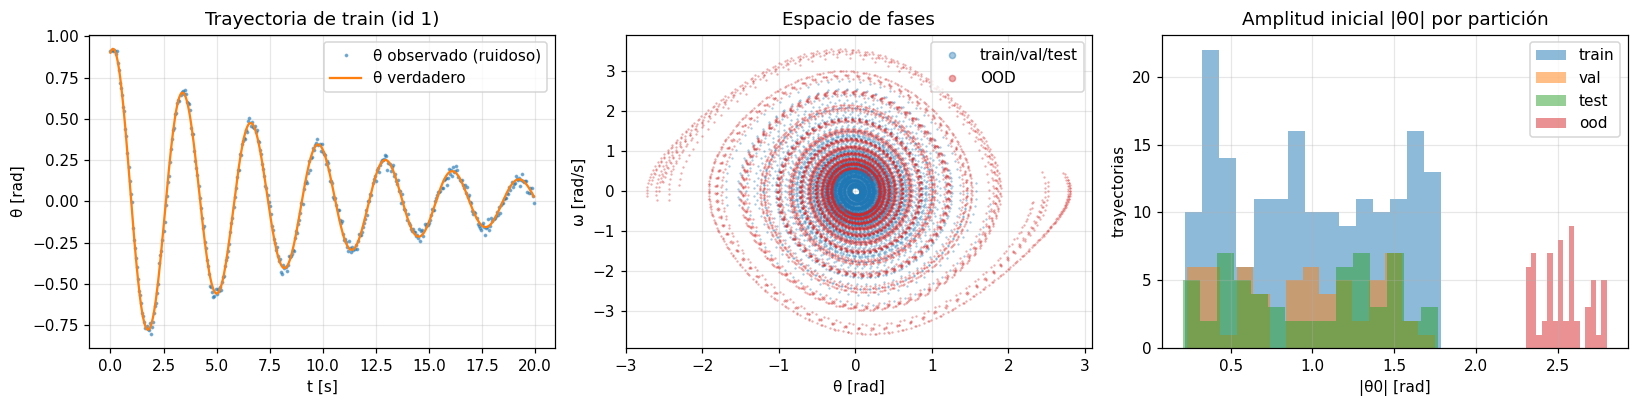

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
i = IDS["train"][0]; t = DAT["t"]
ax[0].plot(t, DAT["obs"][i], ".", ms=3, alpha=0.5, label="θ observado (ruidoso)")
ax[0].plot(t, DAT["theta"][i], lw=1.5, label="θ verdadero")
ax[0].set(title=f"Trayectoria de train (id {i})", xlabel="t [s]", ylabel="θ [rad]"); ax[0].legend()

for nombre, D, c in [("train/val/test", DAT, "C0"), ("OOD", DAT_OOD, "C3")]:
    ax[1].plot(D["theta"][:20].ravel(), D["omega"][:20].ravel(), ".", ms=1, alpha=0.4, color=c, label=nombre)
ax[1].set(title="Espacio de fases", xlabel="θ [rad]", ylabel="ω [rad/s]"); ax[1].legend(markerscale=8)

for nombre in ("train", "val", "test", "ood"):
    ax[2].hist(np.abs(DAT["th0"][IDS[nombre]] if nombre != "ood" else DAT_OOD["th0"]), bins=15, alpha=0.5, label=nombre)
ax[2].set(title="Amplitud inicial |θ0| por partición", xlabel="|θ0| [rad]", ylabel="trayectorias"); ax[2].legend()
plt.tight_layout(); plt.show()

## 3. Línea base, modelo y selección

**Métrica primaria:** RMSE de $\theta(t+H)$ en radianes, calculado desde el paso `calentamiento` de cada ventana (así todos los modelos tienen al menos 20 observaciones de contexto). La pérdida de entrenamiento es el MSE sobre esos mismos pasos.

> Nota: la pérdida del Integrante 1 promedia sobre todos los $T$ pasos. Aquí se excluyen los primeros 19 porque la MLP y Ridge no pueden predecir con menos de 20 observaciones; así todos los modelos se entrenan y evalúan sobre exactamente lo mismo.

**Modelos comparados** (misma partición, misma métrica):

| Modelo | Tipo | Qué ve |
|---|---|---|
| Persistencia | ingenua | $\hat y(t)=x(t)$ |
| Media | ingenua | constante (media de train) |
| Ridge (20 rezagos) | clásica | últimas 20 observaciones, regresión lineal |
| MLP (20 rezagos) | neuronal sin memoria | últimas 20 observaciones |
| GRU | neuronal recurrente | toda la secuencia |
| LNN | objeto de estudio | toda la secuencia (ODE) |

Los hiperparámetros se fijan de antemano (sin búsqueda), salvo $\alpha$ de Ridge, que se elige con **validation**. El conjunto de test se abre **una sola vez por (modelo, semilla)**; la función `abrir_test` lo impone.

In [7]:
# ---------- Métrica ----------
def rmse_rad(pred, Y):
    w = CONFIG.calentamiento
    return float(np.sqrt(np.mean((pred[:, w:] - Y[:, w:]) ** 2)) * SD)

def rmse_por_ventana(pred, Y):
    w = CONFIG.calentamiento
    return np.sqrt(np.mean((pred[:, w:] - Y[:, w:]) ** 2, axis=(1, 2))) * SD

# ---------- Sistema de registro (extiende la tabla de la plantilla con métrica_ood) ----------
columnas_resultado = ["modelo", "parámetros_entrenables", "tiempo_s", "métrica_validation",
                      "métrica_test", "semilla", "observaciones", "métrica_ood"]
resultados = pd.DataFrame(columns=columnas_resultado)

def registrar_resultado(tabla, **fila):
    faltantes = set(columnas_resultado) - set(fila)
    if faltantes: raise ValueError(f"Faltan campos: {sorted(faltantes)}")
    return pd.concat([tabla, pd.DataFrame([fila])], ignore_index=True)

CORRIDAS = {}        # (modelo, semilla) -> predicciones e historia de entrenamiento
MODELOS = {}         # (modelo, semilla) -> modelo entrenado (solo redes)
_TEST_ABIERTO = set()

def abrir_test(clave):
    """Entrega test y OOD. Cada (modelo, semilla) puede abrirlos UNA sola vez."""
    if clave in _TEST_ABIERTO:
        raise RuntimeError(f"El test ya fue abierto para {clave}: no se puede reutilizar para ajustar nada.")
    _TEST_ABIERTO.add(clave)
    return PART["test"], PART["ood"]

def evaluar_y_registrar(nombre, semilla, predictor, n_par, tiempo_s, obs="", historia=None):
    """predictor: función X(np) -> predicción (np) con la misma forma que X."""
    global resultados
    m_val = rmse_rad(predictor(PART["val"]["X"]), PART["val"]["Y"])
    te, ood = abrir_test((nombre, semilla))
    p_te, p_ood = predictor(te["X"]), predictor(ood["X"])
    resultados = registrar_resultado(
        resultados, modelo=nombre, parámetros_entrenables=n_par, tiempo_s=tiempo_s,
        métrica_validation=m_val, métrica_test=rmse_rad(p_te, te["Y"]), semilla=semilla,
        observaciones=obs, métrica_ood=rmse_rad(p_ood, ood["Y"]))
    CORRIDAS[(nombre, semilla)] = dict(pred_test=p_te, pred_ood=p_ood, historia=historia)

N_PERSIST, N_MEDIA, N_RIDGE = "Ingenua: persistencia", "Ingenua: media", "Ridge (20 rezagos)"
N_MLP, N_GRU = "MLP (20 rezagos)", "GRU"

In [8]:
# ---------- Líneas base ingenuas y clásica ----------
def pred_persistencia(X):
    return X.copy()                                        # ŷ(t) = x(t)

MEDIA_TRAIN = float(PART["train"]["Y"].mean())
def pred_media(X):
    return np.full_like(X, MEDIA_TRAIN)

K = CONFIG.contexto_mlp
def _rezagos(X):                                           # (n, L, 1) -> (n, L-K+1, K)
    return np.lib.stride_tricks.sliding_window_view(X[..., 0], K, axis=1)

class RidgeVentana:
    def __init__(self, alpha):
        self.alpha = alpha; self.m = Ridge(alpha=alpha)
    def fit(self, p):
        Z = _rezagos(p["X"]); y = p["Y"][:, K - 1:, 0]
        self.m.fit(Z.reshape(-1, K), y.reshape(-1)); return self
    def __call__(self, X):
        Z = _rezagos(X); n = Z.shape[0]
        salida = np.zeros_like(X)
        salida[:, K - 1:, 0] = self.m.predict(Z.reshape(-1, K)).reshape(n, -1)
        return salida

# alpha se elige con VALIDATION (no con test)
candidatos = {a: RidgeVentana(a).fit(PART["train"]) for a in (1e-4, 1e-2, 1.0, 10.0, 100.0)}
val_por_alpha = {a: rmse_rad(m(PART["val"]["X"]), PART["val"]["Y"]) for a, m in candidatos.items()}
alpha_opt = min(val_por_alpha, key=val_por_alpha.get)
print("RMSE val por alpha:", {a: round(v, 5) for a, v in val_por_alpha.items()}, "→ alpha =", alpha_opt)

t0 = time.perf_counter(); ridge = RidgeVentana(alpha_opt).fit(PART["train"]); t_ridge = time.perf_counter() - t0

evaluar_y_registrar(N_PERSIST, 0, pred_persistencia, 0, 0.0, "determinista")
evaluar_y_registrar(N_MEDIA, 0, pred_media, 1, 0.0, "determinista")
evaluar_y_registrar(N_RIDGE, 0, ridge, K + 1, t_ridge, f"determinista, alpha={alpha_opt}")
display(resultados)

RMSE val por alpha: {0.0001: 0.02437, 0.01: 0.02437, 1.0: 0.02437, 10.0: 0.02436, 100.0: 0.02431} → alpha = 100.0


/tmp/ipykernel_3373/368055757.py:18: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  return pd.concat([tabla, pd.DataFrame([fila])], ignore_index=True)


,modelo,parámetros_entrenables,tiempo_s,métrica_validation,métrica_test,semilla,observaciones,métrica_ood
0,Ingenua: persistencia,0,0.000000,0.325638,0.338822,0,determinista,0.656898
1,Ingenua: media,1,0.000000,0.346895,0.361600,0,determinista,0.767376
2,Ridge (20 rezagos),21,0.062092,0.024306,0.026998,0,"determinista, alpha=100.0",0.192699


In [9]:
# ---------- Líneas base neuronales: MLP y GRU ----------
class MLPVentana(nn.Module):
    """MLP sobre las últimas K observaciones. Misma interfaz que la LNN: (B,T,1) -> (B,T,1)."""
    def __init__(self, K=20, ocultas=64, salida=1):
        super().__init__()
        self.K = K
        self.red = nn.Sequential(nn.Linear(K, ocultas), nn.Tanh(),
                                 nn.Linear(ocultas, ocultas), nn.Tanh(),
                                 nn.Linear(ocultas, salida))
    def forward(self, x):
        v = x[..., 0].unfold(1, self.K, 1)                     # (B, T-K+1, K)
        y = self.red(v)                                        # (B, T-K+1, salida)
        pad = torch.zeros(x.shape[0], self.K - 1, y.shape[-1], device=x.device)
        return torch.cat([pad, y], dim=1)                      # (B, T, salida)

class GRUBase(nn.Module):
    """GRU con capa lineal de salida; ocultas=18 deja ~1150 parámetros, similar a la LNN (1185)."""
    def __init__(self, entrada=1, ocultas=18, salida=1):
        super().__init__()
        self.gru = nn.GRU(entrada, ocultas, batch_first=True)
        self.cabeza = nn.Linear(ocultas, salida)
    def forward(self, x):
        h, _ = self.gru(x)
        return self.cabeza(h)

def contar_parametros(modelo):
    return sum(p.numel() for p in modelo.parameters() if p.requires_grad)

# ---------- Tubería de entrenamiento (la usan TODAS las redes, incluida la LNN) ----------
@torch.no_grad()
def predecir(modelo, X, lote=512):
    modelo.eval()
    return np.concatenate([modelo(torch.from_numpy(X[i:i + lote])).numpy() for i in range(0, len(X), lote)])

def entrenar(fabrica, semilla, cfg=CONFIG):
    """Adam + BPTT, parada temprana por MSE de validation (paciencia), restaura el mejor estado.
    Devuelve (modelo, historia DataFrame, tiempo_s, época_mejor). NO toca el test."""
    torch.manual_seed(semilla); np.random.seed(semilla)
    modelo = fabrica()
    opt = torch.optim.Adam(modelo.parameters(), lr=cfg.tasa_aprendizaje, weight_decay=cfg.decaimiento_pesos)
    w = cfg.calentamiento
    Xtr, Ytr = torch.from_numpy(PART["train"]["X"]), torch.from_numpy(PART["train"]["Y"])
    Xva, Yva = PART["val"]["X"], PART["val"]["Y"]
    gen = torch.Generator().manual_seed(semilla)
    mejor, estado, sin_mejora, ep_mejor, hist = np.inf, None, 0, 0, []
    t0 = time.perf_counter()
    for ep in range(cfg.épocas_máximas):
        modelo.train()
        perm = torch.randperm(len(Xtr), generator=gen)
        acum = 0.0
        for i in range(0, len(perm), cfg.tamaño_lote):
            idx = perm[i:i + cfg.tamaño_lote]
            perdida = torch.mean((modelo(Xtr[idx])[:, w:] - Ytr[idx][:, w:]) ** 2)
            opt.zero_grad(); perdida.backward()
            nn.utils.clip_grad_norm_(modelo.parameters(), cfg.recorte_gradiente)
            opt.step()
            acum += perdida.item() * len(idx)
        mse_va = float(np.mean((predecir(modelo, Xva)[:, w:] - Yva[:, w:]) ** 2))
        hist.append({"época": ep, "mse_train": acum / len(Xtr), "mse_val": mse_va})
        if mse_va < mejor - 1e-7:
            mejor, estado, sin_mejora, ep_mejor = mse_va, copy.deepcopy(modelo.state_dict()), 0, ep
        else:
            sin_mejora += 1
            if sin_mejora >= cfg.paciencia: break
    modelo.load_state_dict(estado)
    return modelo, pd.DataFrame(hist), time.perf_counter() - t0, ep_mejor

FABRICAS = {
    N_MLP: lambda: MLPVentana(K=CONFIG.contexto_mlp, ocultas=64),
    N_GRU: lambda: GRUBase(ocultas=18),
}

def correr(nombre, semilla):
    clave = (nombre, semilla)
    if clave in CORRIDAS: return                           # reanuda sin repetir ni reabrir el test
    modelo, hist, t_s, ep = entrenar(FABRICAS[nombre], semilla)
    MODELOS[clave] = modelo
    evaluar_y_registrar(nombre, semilla, lambda X: predecir(modelo, X), contar_parametros(modelo),
                        t_s, f"época_mejor={ep}", historia=hist)
    print(f"{nombre:<28s} semilla {semilla}: {t_s:6.1f} s, mejor época {ep}, "
          f"RMSE val = {resultados.iloc[-1]['métrica_validation']:.4f} rad")

In [10]:
for s in CONFIG.semillas:
    for nombre in (N_MLP, N_GRU):
        correr(nombre, s)

MLP (20 rezagos)             semilla 0:   17.6 s, mejor época 35, RMSE val = 0.0108 rad
GRU                          semilla 0:   68.6 s, mejor época 97, RMSE val = 0.0081 rad
MLP (20 rezagos)             semilla 1:    9.5 s, mejor época 21, RMSE val = 0.0116 rad
GRU                          semilla 1:   65.0 s, mejor época 97, RMSE val = 0.0077 rad
MLP (20 rezagos)             semilla 2:    7.8 s, mejor época 24, RMSE val = 0.0111 rad
GRU                          semilla 2:   57.1 s, mejor época 78, RMSE val = 0.0092 rad
MLP (20 rezagos)             semilla 3:   13.7 s, mejor época 44, RMSE val = 0.0109 rad
GRU                          semilla 3:   59.4 s, mejor época 80, RMSE val = 0.0085 rad
MLP (20 rezagos)             semilla 4:    9.9 s, mejor época 31, RMSE val = 0.0118 rad
GRU                          semilla 4:   64.6 s, mejor época 99, RMSE val = 0.0077 rad


## 4. Evidencia: experimentos, ablaciones y diagnóstico

### 4.0 Modelos de la LNN y ablaciones

Las dos ablaciones arquitectónicas son:

- **(a) Constante de tiempo fija vs. líquida.** En la LTC la conductancia $f$ aparece en el término de decaimiento, de modo que $\tau_{ef}=\tau/(1+\tau f)$ cambia con el estado. Ablación: $\dot h=-h/\tau+f\,A$ (la no linealidad solo *impulsa* el estado y $\tau_{ef}=\tau$ queda fija). Tiene exactamente el mismo número de parámetros.
- **(b) Tamaño de la capa oculta** $N_h\in\{8,16,32\}$ (base: 32). Muestra cuánta capacidad necesita el sistema.

La clase de ablación hereda de `LiquidCell` del Integrante 1; con `tau_fija=False` es idéntica a su modelo (se verifica numéricamente).

In [11]:
class CeldaLiquidaAbl(LiquidCell):
    """Igual a LiquidCell, con opción de congelar la constante de tiempo efectiva (ablación a)."""
    def __init__(self, in_features, hidden_features, dt=0.1, tau_fija=False):
        super().__init__(in_features, hidden_features, dt)
        self.tau_fija = tau_fija
    def forward(self, x):
        B, T, _ = x.shape
        h = torch.zeros(B, self.hidden_features, device=x.device)
        tau = torch.abs(self.tau_raw) + 1e-3
        salidas = []
        for t in range(T):
            f = torch.sigmoid(x[:, t, :] @ self.w_in.t() + h @ self.w_rec.t() + self.bias)
            if self.tau_fija:
                dh = -h / tau + f * self.A                  # τ_ef = τ (constante)
            else:
                dh = -((1.0 / tau) + f) * h + f * self.A    # τ_ef = 1/(1/τ + f) (líquida)
            h = h + self.dt * dh
            salidas.append(h)
        return torch.stack(salidas, dim=1)

class LNNAblacion(nn.Module):
    def __init__(self, in_features, hidden_features, out_features, dt=0.1, tau_fija=False):
        super().__init__()
        self.liquid_layer = CeldaLiquidaAbl(in_features, hidden_features, dt, tau_fija)
        self.head = nn.Linear(hidden_features, out_features)
    def forward(self, x):
        return self.head(self.liquid_layer(x))

# ---- Verificaciones: la ablación base == modelo del I1; formas y conteo de parámetros == fórmula 1.4 ----
_ref = LiquidNeuralNetwork(1, 32, 1, dt=CONFIG.paso_muestreo)
_abl = LNNAblacion(1, 32, 1, dt=CONFIG.paso_muestreo, tau_fija=False)
_abl.load_state_dict(_ref.state_dict())
_x = torch.randn(4, CONFIG.largo_ventana, 1)
assert _ref(_x).shape == (4, CONFIG.largo_ventana, 1), "forma de salida inesperada"
assert torch.allclose(_ref(_x), _abl(_x), atol=1e-6), "la ablación base NO coincide con el modelo del I1"
N_i, N_h, N_o = 1, 32, 1
assert contar_parametros(_ref) == N_h * (N_i + N_h + N_o + 3) + N_o, "no coincide con la fórmula de la sección 1.4"
ESTADO["formas_ok"] = True
print("OK: formas, equivalencia con el I1 y conteo de parámetros =", contar_parametros(_ref))

N_LNN = "LNN (base, N_h=32)"
N_TAUFIJA = "Abl. (a): τ fija"
N_H8, N_H16 = "Abl. (b): N_h=8", "Abl. (b): N_h=16"
dt_m = CONFIG.paso_muestreo
FABRICAS.update({
    N_LNN:     lambda: LiquidNeuralNetwork(1, 32, 1, dt=dt_m),
    N_TAUFIJA: lambda: LNNAblacion(1, 32, 1, dt=dt_m, tau_fija=True),
    N_H8:      lambda: LiquidNeuralNetwork(1, 8, 1, dt=dt_m),
    N_H16:     lambda: LiquidNeuralNetwork(1, 16, 1, dt=dt_m),
})

OK: formas, equivalencia con el I1 y conteo de parámetros = 1185


In [12]:
# Entrena todas las variantes LNN con todas las semillas (puede tardar varios minutos en CPU).
# Si el runtime se corta, volver a ejecutar: las corridas ya hechas se saltan.
for s in CONFIG.semillas:
    for nombre in (N_LNN, N_TAUFIJA, N_H8, N_H16):
        correr(nombre, s)

LNN (base, N_h=32)           semilla 0:   71.4 s, mejor época 98, RMSE val = 0.0163 rad
Abl. (a): τ fija             semilla 0:   63.5 s, mejor época 98, RMSE val = 0.0157 rad
Abl. (b): N_h=8              semilla 0:   63.2 s, mejor época 98, RMSE val = 0.0264 rad
Abl. (b): N_h=16             semilla 0:   63.5 s, mejor época 99, RMSE val = 0.0189 rad
LNN (base, N_h=32)           semilla 1:   71.5 s, mejor época 98, RMSE val = 0.0166 rad
Abl. (a): τ fija             semilla 1:   63.0 s, mejor época 98, RMSE val = 0.0159 rad
Abl. (b): N_h=8              semilla 1:   63.2 s, mejor época 99, RMSE val = 0.0236 rad
Abl. (b): N_h=16             semilla 1:   64.6 s, mejor época 99, RMSE val = 0.0182 rad
LNN (base, N_h=32)           semilla 2:   71.1 s, mejor época 99, RMSE val = 0.0162 rad
Abl. (a): τ fija             semilla 2:   62.0 s, mejor época 98, RMSE val = 0.0154 rad
Abl. (b): N_h=8              semilla 2:   63.5 s, mejor época 99, RMSE val = 0.0234 rad
Abl. (b): N_h=16             sem

### 4.1 Curvas de entrenamiento y criterio de parada

Se entrena con Adam y BPTT. **Criterio de parada:** se detiene si el MSE de validation no mejora durante `paciencia` épocas consecutivas (o al llegar a `épocas_máximas`) y se restaura el estado de la mejor época (línea punteada). Las curvas muestran todas las semillas; MSE en rad².

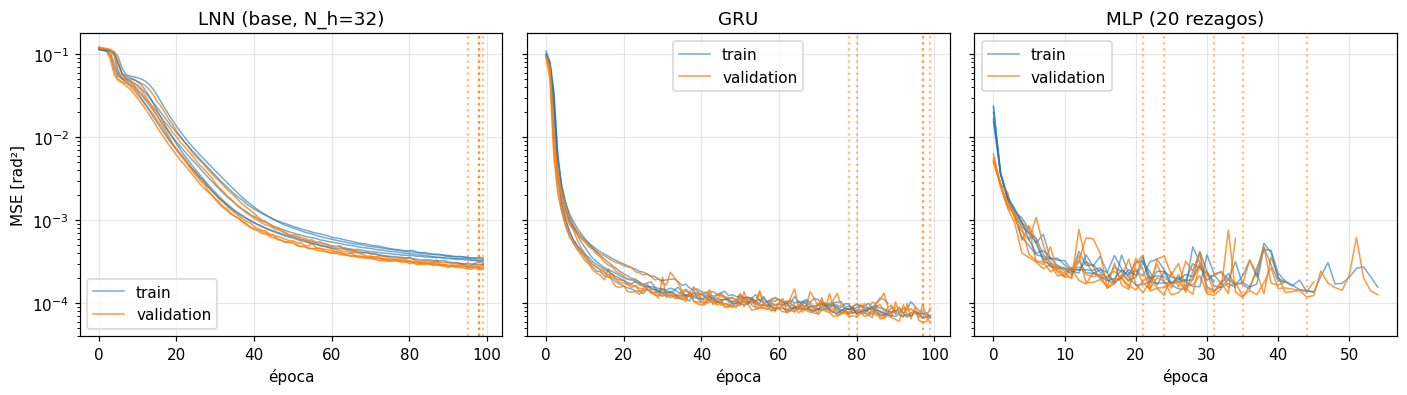

In [13]:
def graficar_curvas(nombres):
    fig, ejes = plt.subplots(1, len(nombres), figsize=(4.3 * len(nombres), 3.7), sharey=True)
    ejes = np.atleast_1d(ejes)
    for ax, nombre in zip(ejes, nombres):
        for s in CONFIG.semillas:
            h = CORRIDAS[(nombre, s)]["historia"]
            ax.plot(h["época"], h["mse_train"] * SD**2, color="C0", alpha=0.6, lw=1, label="train" if s == CONFIG.semillas[0] else None)
            ax.plot(h["época"], h["mse_val"] * SD**2, color="C1", alpha=0.8, lw=1, label="validation" if s == CONFIG.semillas[0] else None)
            ax.axvline(h["mse_val"].idxmin(), color="C1", ls=":", alpha=0.5)
        ax.set(title=nombre, xlabel="época", yscale="log")
        ax.legend()
    ejes[0].set_ylabel("MSE [rad²]")
    plt.tight_layout(); plt.show()

graficar_curvas([N_LNN, N_GRU, N_MLP])

**Lectura de las curvas.** El presupuesto de entrenamiento se subió de 60 a 100 épocas (paciencia 10, los valores por defecto de la plantilla) porque la curva de validation de la LNN seguía bajando con 60. Con 100 épocas, la LNN alcanzó su mejor época entre la 95 y la 99 en las cinco semillas (igual que sus ablaciones): **no activó la parada temprana** y su curva casi se aplana pero aún baja muy despacio. La GRU tuvo su mejor época entre la 78 y la 99, y la MLP sí activó la parada temprana (terminó antes de la época 55). En las tres arquitecturas train y validation son muy parecidas, sin señal de sobreajuste. Limitación: la LNN pudo mejorar algo más con más épocas.

### 4.2 Métrica primaria con incertidumbre (varias semillas)

Cada semilla cambia la inicialización de pesos y el orden de los lotes (la partición de datos es fija). Se reporta **media ± desviación estándar** entre semillas. Persistencia, media y Ridge son deterministas (desviación 0). Con solo 5 semillas, las desviaciones son estimaciones gruesas.

,n,parámetros,RMSE val [rad],RMSE test [rad],RMSE OOD [rad],OOD / test
modelo,,,,,,
GRU,5,1153,0.0082 ± 0.0007,0.0086 ± 0.0006,0.1199 ± 0.0134,13.93
MLP (20 rezagos),5,5569,0.0112 ± 0.0004,0.0127 ± 0.0007,0.1534 ± 0.0063,12.06
Abl. (a): τ fija,5,1185,0.0162 ± 0.0008,0.0173 ± 0.0008,0.0821 ± 0.0032,4.73
"LNN (base, N_h=32)",5,1185,0.0164 ± 0.0004,0.0174 ± 0.0005,0.0934 ± 0.0053,5.37
Abl. (b): N_h=16,5,337,0.0185 ± 0.0007,0.0199 ± 0.0009,0.1120 ± 0.0068,5.62
Abl. (b): N_h=8,5,105,0.0244 ± 0.0012,0.0268 ± 0.0018,0.1328 ± 0.0108,4.96
Ridge (20 rezagos),1,21,0.0243 ± 0.0000,0.0270 ± 0.0000,0.1927 ± 0.0000,7.14
Ingenua: persistencia,1,0,0.3256 ± 0.0000,0.3388 ± 0.0000,0.6569 ± 0.0000,1.94
Ingenua: media,1,1,0.3469 ± 0.0000,0.3616 ± 0.0000,0.7674 ± 0.0000,2.12


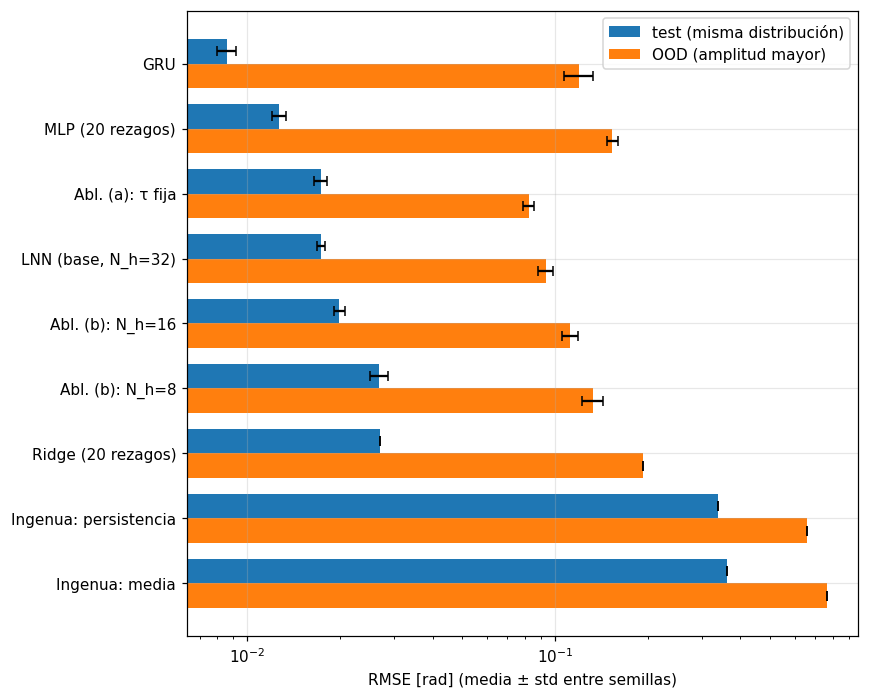

In [14]:
COLS_NUM = ["métrica_validation", "métrica_test", "métrica_ood", "parámetros_entrenables", "tiempo_s"]

def tabla_resumen():
    r = resultados.copy(); r[COLS_NUM] = r[COLS_NUM].astype(float)
    g = r.groupby("modelo", sort=False)[COLS_NUM]
    return g.mean(), g.std().fillna(0.0), r.groupby("modelo", sort=False).size()

media, desv, n_sem = tabla_resumen()
orden = media["métrica_test"].sort_values().index
fmt = lambda c: [f"{media.loc[m, c]:.4f} ± {desv.loc[m, c]:.4f}" for m in orden]
vista = pd.DataFrame({"n": n_sem.loc[orden].values,
                      "parámetros": media.loc[orden, "parámetros_entrenables"].astype(int).values,
                      "RMSE val [rad]": fmt("métrica_validation"),
                      "RMSE test [rad]": fmt("métrica_test"),
                      "RMSE OOD [rad]": fmt("métrica_ood"),
                      "OOD / test": (media.loc[orden, "métrica_ood"] / media.loc[orden, "métrica_test"]).round(2).values},
                     index=orden)
display(vista)

fig, ax = plt.subplots(figsize=(8, 0.55 * len(orden) + 1.5))
y, h = np.arange(len(orden)), 0.38
ax.barh(y - h/2, media.loc[orden, "métrica_test"], h, xerr=desv.loc[orden, "métrica_test"], capsize=3, label="test (misma distribución)")
ax.barh(y + h/2, media.loc[orden, "métrica_ood"], h, xerr=desv.loc[orden, "métrica_ood"], capsize=3, label="OOD (amplitud mayor)")
ax.set(yticks=y, yticklabels=orden, xscale="log", xlabel="RMSE [rad] (media ± std entre semillas)")
ax.invert_yaxis(); ax.legend(); plt.tight_layout(); plt.show()

In [15]:
# ---- Evaluación automática de las predicciones falsables H1 y H2 ----
m_b, s_b = media.loc[N_LNN, "métrica_test"], desv.loc[N_LNN, "métrica_test"]
m_f, s_f = media.loc[N_TAUFIJA, "métrica_test"], desv.loc[N_TAUFIJA, "métrica_test"]
disp = float(np.hypot(s_b, s_f))
H1 = (m_f - m_b) > disp
print(f"H1  RMSE test: LNN líquida {m_b:.4f}±{s_b:.4f}  vs  τ fija {m_f:.4f}±{s_f:.4f}")
print(f"    diferencia = {m_f - m_b:+.4f} rad; dispersión combinada = {disp:.4f} rad  →  H1 {'SE SOSTIENE' if H1 else 'NO se sostiene (falsada)'}")

razon = media["métrica_ood"] / media["métrica_test"]
H2 = razon[N_LNN] < min(razon[N_MLP], razon[N_GRU])
print(f"H2  OOD/test: LNN {razon[N_LNN]:.2f} | MLP {razon[N_MLP]:.2f} | GRU {razon[N_GRU]:.2f}  →  H2 {'SE SOSTIENE' if H2 else 'NO se sostiene (falsada)'}")
_comp = (N_GRU, N_MLP, N_RIDGE)
_sup = [m for m in _comp if media.loc[N_LNN, "métrica_test"] < media.loc[m, "métrica_test"]]
_no = [m for m in _comp if m not in _sup]
print("\nMejor modelo en test:", orden[0])
print("La LNN supera en test a:", ", ".join(_sup) if _sup else "ninguno de GRU/MLP/Ridge", "| NO supera a:", ", ".join(_no) if _no else "ninguno")

H1  RMSE test: LNN líquida 0.0174±0.0005  vs  τ fija 0.0173±0.0008
    diferencia = -0.0001 rad; dispersión combinada = 0.0010 rad  →  H1 NO se sostiene (falsada)
H2  OOD/test: LNN 5.37 | MLP 12.06 | GRU 13.93  →  H2 SE SOSTIENE

Mejor modelo en test: GRU
La LNN supera en test a: Ridge (20 rezagos) | NO supera a: GRU, MLP (20 rezagos)


**Lectura de la tabla y de H1/H2.**

- **Test:** GRU 0.0086 ± 0.0006 < MLP 0.0127 ± 0.0007 < LNN 0.0174 ± 0.0005 ≈ LNN con τ fija 0.0173 ± 0.0008 < Ridge 0.0270. La GRU, con casi los mismos parámetros que la LNN (1153 vs 1185), es ≈2× mejor. La LNN supera a Ridge (−36 %) y mejora ≈19 veces a la persistencia (0.3388).
- **OOD:** LNN 0.0934 ± 0.0053 frente a GRU 0.1199 ± 0.0134 (diferencia de ≈1.8 desviaciones combinadas: evidencia moderada con 5 semillas), MLP 0.1534 y Ridge 0.1927. La variante de τ fija es la mejor: 0.0821 ± 0.0032.
- **H1 no se sostiene:** en test la diferencia entre τ fija y líquida (−0.0001 rad) es menor que la dispersión combinada (0.0010 rad). En OOD, la τ fija es incluso ≈12 % mejor.
- **H2 se sostiene:** OOD/test = 5.37 en la LNN frente a 12.06 (MLP) y 13.93 (GRU); además, en valor absoluto la LNN queda por debajo de ambas en OOD.
- La última línea de la celda indica contra qué modelos gana la LNN en test: supera a Ridge y a las líneas ingenuas, pero no a GRU ni MLP.

### 4.2b Comparación completa contra todas las referencias

La celda anterior evalúa H1 y H2 tal como se definen en §2.1 (H1: líquida vs. τ fija; H2: cociente OOD/test). Como el cociente OOD/test puede verse favorecido cuando el error de test ya es alto, aquí se comparan también los **RMSE absolutos** de la LNN contra cada referencia, con el mismo criterio de dispersión combinada (raíz de la suma de cuadrados de las desviaciones entre semillas). Se computa a partir de la tabla de §4.2; no entrena nada ni abre el test de nuevo.

In [16]:
def comparar_con_lnn(ref, col):
    """Diferencia (ref - LNN) y dispersión combinada. Positivo => la LNN tiene menor error."""
    d = float(media.loc[ref, col] - media.loc[N_LNN, col])
    disp = float(np.hypot(desv.loc[ref, col], desv.loc[N_LNN, col]))
    return d, disp

filas_cmp = []
for col_cmp, etiqueta in [("métrica_test", "RMSE test (misma distribución)"), ("métrica_ood", "RMSE OOD (amplitud mayor)")]:
    for ref in (N_GRU, N_MLP, N_RIDGE, N_TAUFIJA):
        d, disp = comparar_con_lnn(ref, col_cmp)
        veredicto = "LNN mejor" if d > max(disp, 1e-12) else ("LNN peor" if d < -max(disp, 1e-12) else "empate (dentro de la dispersión)")
        filas_cmp.append({"métrica": etiqueta, "referencia": ref,
                          "RMSE referencia [rad]": round(float(media.loc[ref, col_cmp]), 4),
                          "RMSE LNN [rad]": round(float(media.loc[N_LNN, col_cmp]), 4),
                          "cambio relativo de la LNN [%]": round(-100 * d / float(media.loc[ref, col_cmp]), 1),
                          "dispersión combinada [rad]": round(disp, 4), "veredicto": veredicto})
display(pd.DataFrame(filas_cmp))

,métrica,referencia,RMSE referencia [rad],RMSE LNN [rad],cambio relativo de la LNN [%],dispersión combinada [rad],veredicto
0,RMSE test (misma distribución),GRU,0.0086,0.0174,102.1,0.0008,LNN peor
1,RMSE test (misma distribución),MLP (20 rezagos),0.0127,0.0174,36.8,0.0009,LNN peor
2,RMSE test (misma distribución),Ridge (20 rezagos),0.0270,0.0174,-35.6,0.0005,LNN mejor
3,RMSE test (misma distribución),Abl. (a): τ fija,0.0173,0.0174,0.3,0.0010,empate (dentro de la dispersión)
4,RMSE OOD (amplitud mayor),GRU,0.1199,0.0934,-22.1,0.0144,LNN mejor
5,RMSE OOD (amplitud mayor),MLP (20 rezagos),0.1534,0.0934,-39.1,0.0082,LNN mejor
6,RMSE OOD (amplitud mayor),Ridge (20 rezagos),0.1927,0.0934,-51.5,0.0053,LNN mejor
7,RMSE OOD (amplitud mayor),Abl. (a): τ fija,0.0821,0.0934,13.8,0.0062,LNN peor


**Lectura de 4.2b.** El «cambio relativo» se mide respecto al error de la referencia (negativo = la LNN tiene menos error).

- **Test:** la LNN es peor que la GRU (+102 %) y que la MLP (+37 %), mejor que Ridge (−36 %) y empata con la versión de τ fija (+0.3 %, dentro de la dispersión combinada de 0.0010 rad).
- **OOD:** la LNN es mejor que la GRU (−22 %), la MLP (−39 %) y Ridge (−52 %), y peor que la versión de τ fija (+14 %). Nótese que la base del porcentaje cambia: en §4.5 la τ fija aparece como −12 % *respecto a la LNN*; aquí la LNN aparece como +14 % *respecto a la τ fija*; es la misma diferencia de 0.011 rad.
- **Qué tan firme es la ventaja OOD:** frente a la GRU la diferencia (0.0265 rad) es solo ≈1.8 veces la dispersión combinada (0.0144 rad), así que con 5 semillas es evidencia moderada; frente a MLP (0.0600 rad contra 0.0082) y Ridge la diferencia es claramente mayor que la dispersión. Esto confirma que H2 no depende de que el error de test de la LNN sea más alto.

### 4.3 Residuos

Problema de regresión: en lugar de matriz de confusión se muestran residuos $e=\hat\theta-\theta$ en el conjunto de test (semilla `CONFIG.semillas[0]`). Un buen modelo tiene residuos centrados en 0, sin estructura en función de $\theta$ ni de la velocidad, y un error que no crece con el tiempo de contexto.

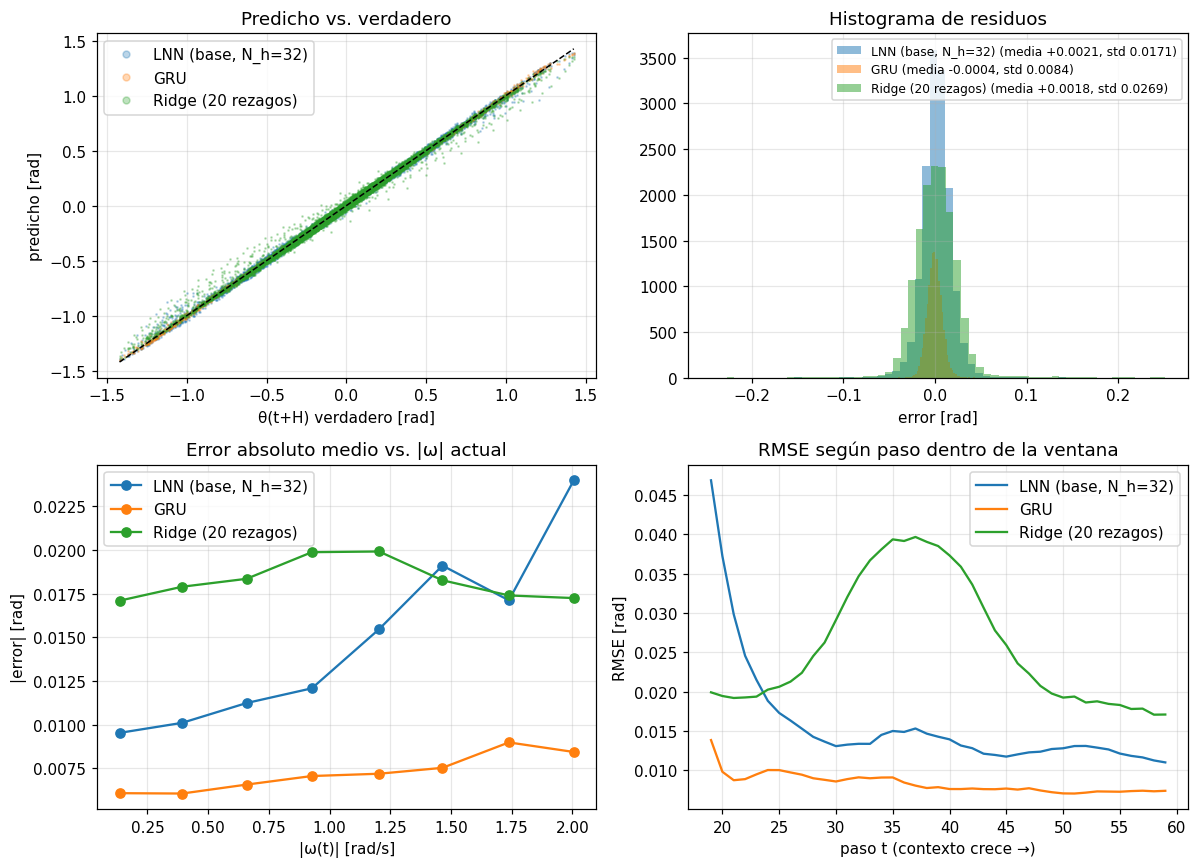

In [17]:
SEM0 = CONFIG.semillas[0]
def residuos_figura(nombres):
    P = PART["test"]; w = CONFIG.calentamiento
    Yr = (P["Y"][:, w:, 0] * SD + MU).ravel()
    vel = np.abs(P["omega"][:, w:, 0]).ravel()
    fig, ax = plt.subplots(2, 2, figsize=(11, 8))
    bins_v = np.linspace(0, np.quantile(vel, 0.99), 9)
    for k, nombre in enumerate(nombres):
        pred = CORRIDAS[(nombre, SEM0)]["pred_test"]
        e = ((pred[:, w:, 0] - P["Y"][:, w:, 0]) * SD)
        ax[0, 0].plot(Yr, (e.ravel() + Yr), ".", ms=1.5, alpha=0.3, color=f"C{k}", label=nombre)
        ax[0, 1].hist(e.ravel(), bins=60, alpha=0.5, color=f"C{k}", label=f"{nombre} (media {e.mean():+.4f}, std {e.std():.4f})")
        idx = np.digitize(vel, bins_v)
        ax[1, 0].plot([vel[idx == b].mean() for b in range(1, len(bins_v)) if (idx == b).any()],
                      [np.abs(e.ravel()[idx == b]).mean() for b in range(1, len(bins_v)) if (idx == b).any()], "o-", color=f"C{k}", label=nombre)
        ax[1, 1].plot(np.arange(w, CONFIG.largo_ventana), np.sqrt((e**2).mean(axis=0)), color=f"C{k}", label=nombre)
    lim = [Yr.min(), Yr.max()]
    ax[0, 0].plot(lim, lim, "k--", lw=1); ax[0, 0].set(title="Predicho vs. verdadero", xlabel="θ(t+H) verdadero [rad]", ylabel="predicho [rad]"); ax[0, 0].legend(markerscale=6)
    ax[0, 1].set(title="Histograma de residuos", xlabel="error [rad]"); ax[0, 1].legend(fontsize=8)
    ax[1, 0].set(title="Error absoluto medio vs. |ω| actual", xlabel="|ω(t)| [rad/s]", ylabel="|error| [rad]"); ax[1, 0].legend()
    ax[1, 1].set(title="RMSE según paso dentro de la ventana", xlabel="paso t (contexto crece →)", ylabel="RMSE [rad]"); ax[1, 1].legend()
    plt.tight_layout(); plt.show()

residuos_figura([N_LNN, N_GRU, N_RIDGE])

**Lectura de los residuos.** Los residuos están centrados: LNN media +0.0021 rad (std 0.0171), GRU −0.0004 (0.0084), Ridge +0.0018 (0.0269); en el gráfico predicho-verdadero los tres modelos siguen la diagonal. El error de la LNN crece con la velocidad (≈0.0095 rad con |ω|≈0.1 rad/s → ≈0.024 rad con |ω|≈2 rad/s), mientras que el de la GRU se mantiene entre 0.006 y 0.009 rad y el de Ridge entre 0.017 y 0.020 rad. Según el paso dentro de la ventana, el RMSE de la LNN baja de ≈0.047 rad (paso 19) a ≈0.013 rad (paso ≈30): necesita unos 10 pasos más de contexto, mientras que la GRU parte de ≈0.014 rad. Ridge muestra un máximo de ≈0.04 rad hacia los pasos 35–38 cuya causa no se investigó.

### 4.4 Costo computacional y huella aproximada

Tiempo medido en este runtime (entrenamiento completo con validation). La energía y el CO₂e son **estimaciones con supuestos explícitos**; ajústelos a la máquina real si se conocen.

In [18]:
POTENCIA_CPU_W = 15.0       # SUPUESTO: potencia media de la CPU del runtime de Colab
FACTOR_CO2_KG_KWH = 0.20    # SUPUESTO: intensidad de carbono de la red eléctrica (kg CO2e por kWh)

def latencia_ms(modelo, X, reps=5):
    predecir(modelo, X[:32])
    t0 = time.perf_counter()
    for _ in range(reps): predecir(modelo, X)
    return 1e3 * (time.perf_counter() - t0) / reps / len(X)

nombres_nn = [N_MLP, N_GRU, N_LNN, N_TAUFIJA, N_H8, N_H16]
filas = []
for m in nombres_nn:
    t_med = media.loc[m, "tiempo_s"]
    filas.append({"modelo": m,
                  "parámetros": int(media.loc[m, "parámetros_entrenables"]),
                  "tiempo/entrenamiento [s]": round(t_med, 1),
                  "energía est. [Wh]": round(POTENCIA_CPU_W * t_med / 3600, 3),
                  "CO2e est. [g]": round(POTENCIA_CPU_W * t_med / 3600 * FACTOR_CO2_KG_KWH, 3),
                  "inferencia [ms/ventana]": round(latencia_ms(MODELOS[(m, SEM0)], PART["test"]["X"]), 3)})
costo = pd.DataFrame(filas).set_index("modelo"); display(costo)
t_total = resultados["tiempo_s"].astype(float).sum()
print(f"Cómputo total del proyecto (suma de entrenamientos): {t_total/60:.1f} min ≈ {POTENCIA_CPU_W*t_total/3600:.2f} Wh "
      f"≈ {POTENCIA_CPU_W*t_total/3600*FACTOR_CO2_KG_KWH:.2f} g CO2e (con los supuestos indicados).")

,parámetros,tiempo/entrenamiento [s],energía est. [Wh],CO2e est. [g],inferencia [ms/ventana]
modelo,,,,,
MLP (20 rezagos),5569,11.7,0.049,0.010,0.033
GRU,1153,62.9,0.262,0.052,0.034
"LNN (base, N_h=32)",1185,71.2,0.297,0.059,0.026
Abl. (a): τ fija,1185,63.1,0.263,0.053,0.024
Abl. (b): N_h=8,105,63.2,0.263,0.053,0.017
Abl. (b): N_h=16,337,64.6,0.269,0.054,0.020


Cómputo total del proyecto (suma de entrenamientos): 28.1 min ≈ 7.01 Wh ≈ 1.40 g CO2e (con los supuestos indicados).


**Lectura del costo.** Entrenamiento por corrida: MLP ≈10 s, GRU ≈57 s, LNN ≈66 s (≈16 % más que la GRU); energía estimada 0.042, 0.238 y 0.276 Wh (supuestos: 15 W y 0.20 kg CO₂e/kWh). Todo el proyecto sumó ≈25.8 min ≈ 6.46 Wh ≈ 1.29 g CO₂e. La inferencia cuesta casi lo mismo en todos los modelos (0.017–0.030 ms por ventana). La MLP tarda menos porque la parada temprana la detuvo antes, no porque cada época sea más rápida. Las variantes de la LNN con N_h = 8, 16 y 32 tardan entre 58 y 66 s: el costo lo domina el recorrido paso a paso de la secuencia más que el tamaño de la capa.

### 4.5 Ablaciones

Mismas semillas, partición y métrica que el modelo base. $\Delta\%$ es el cambio relativo del RMSE respecto a la LNN base (positivo = peor).

In [19]:
def tabla_ablaciones():
    grupos = {"(a) Constante de tiempo": [N_LNN, N_TAUFIJA],
              "(b) Tamaño de la capa oculta": [N_H8, N_H16, N_LNN]}
    for titulo, nombres in grupos.items():
        sub = pd.DataFrame({
            "parámetros": media.loc[nombres, "parámetros_entrenables"].astype(int),
            "RMSE test [rad]": [f"{media.loc[m,'métrica_test']:.4f} ± {desv.loc[m,'métrica_test']:.4f}" for m in nombres],
            "Δ% test": (100 * (media.loc[nombres, "métrica_test"] / media.loc[N_LNN, "métrica_test"] - 1)).round(1),
            "RMSE OOD [rad]": [f"{media.loc[m,'métrica_ood']:.4f} ± {desv.loc[m,'métrica_ood']:.4f}" for m in nombres],
            "Δ% OOD": (100 * (media.loc[nombres, "métrica_ood"] / media.loc[N_LNN, "métrica_ood"] - 1)).round(1),
        }, index=nombres)
        print(titulo); display(sub)

tabla_ablaciones()

(a) Constante de tiempo


,parámetros,RMSE test [rad],Δ% test,RMSE OOD [rad],Δ% OOD
"LNN (base, N_h=32)",1185,0.0174 ± 0.0005,0.0,0.0934 ± 0.0053,0.0
Abl. (a): τ fija,1185,0.0173 ± 0.0008,-0.3,0.0821 ± 0.0032,-12.1


(b) Tamaño de la capa oculta


,parámetros,RMSE test [rad],Δ% test,RMSE OOD [rad],Δ% OOD
Abl. (b): N_h=8,105,0.0268 ± 0.0018,54.0,0.1328 ± 0.0108,42.1
Abl. (b): N_h=16,337,0.0199 ± 0.0009,14.5,0.1120 ± 0.0068,19.9
"LNN (base, N_h=32)",1185,0.0174 ± 0.0005,0.0,0.0934 ± 0.0053,0.0


**Lectura de las ablaciones.**

- **(a) τ fija vs. líquida** (mismos 1185 parámetros): en test son indistinguibles (0.0174 vs 0.0173, −0.3 %); en OOD la τ fija es −12.1 % (0.0821 vs 0.0934), diferencia de ≈1.8 desviaciones combinadas. Modular la constante de tiempo con el estado no aportó precisión en este sistema.
- **(b) tamaño de la capa oculta:** al reducir N_h de 32 a 16 y a 8, el RMSE de test sube +14.5 % y +54 %, y el de OOD +19.9 % y +42.1 %. Con N_h = 8 (105 parámetros) la LNN queda al nivel de Ridge (0.0268 vs 0.0270, con 21 parámetros). Más capacidad ayuda en este rango; como todas las variantes terminaron su mejor época entre la 95 y la 99, parte de la diferencia puede deberse a distinta velocidad de convergencia.

### 4.6 Análisis de errores y límites de generalización

Se compara el error por ventana en test (misma distribución) y OOD (amplitudes mayores, más anarmónicas), y se muestran los casos donde la LNN falla más.

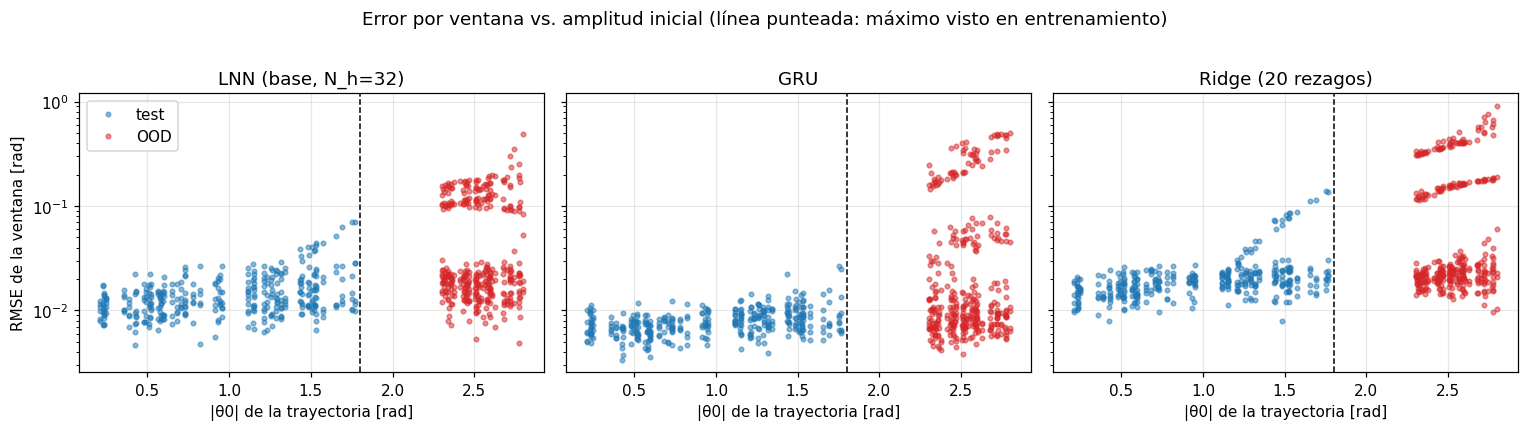

In [20]:
def rmse_ventanas_modelo(nombre, semilla=SEM0):
    c = CORRIDAS[(nombre, semilla)]
    return (rmse_por_ventana(c["pred_test"], PART["test"]["Y"]),
            rmse_por_ventana(c["pred_ood"], PART["ood"]["Y"]))

fig, ejes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, nombre in zip(ejes, [N_LNN, N_GRU, N_RIDGE]):
    e_te, e_ood = rmse_ventanas_modelo(nombre)
    ax.plot(np.abs(PART["test"]["th0"]), e_te, ".", alpha=0.5, label="test")
    ax.plot(np.abs(PART["ood"]["th0"]), e_ood, ".", alpha=0.5, color="C3", label="OOD")
    ax.axvline(RANGO_TH0_TRAIN[1], color="k", ls="--", lw=1)
    ax.set(title=nombre, xlabel="|θ0| de la trayectoria [rad]", yscale="log")
ejes[0].set_ylabel("RMSE de la ventana [rad]"); ejes[0].legend()
plt.suptitle("Error por ventana vs. amplitud inicial (línea punteada: máximo visto en entrenamiento)", y=1.02)
plt.tight_layout(); plt.show()

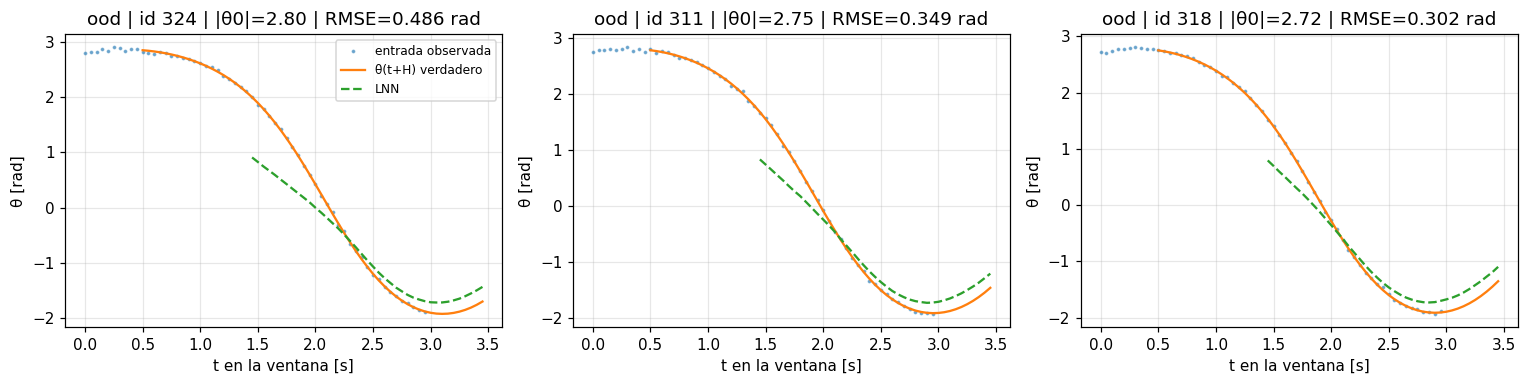

In [21]:
# Las 3 ventanas con peor error de la LNN (test ∪ OOD)
e_te, e_ood = rmse_ventanas_modelo(N_LNN)
E = np.concatenate([e_te, e_ood])
origen = np.array(["test"] * len(e_te) + ["ood"] * len(e_ood))
local = np.concatenate([np.arange(len(e_te)), np.arange(len(e_ood))])
peores = np.argsort(E)[::-1][:3]

fig, ejes = plt.subplots(1, 3, figsize=(14, 3.6))
tt = np.arange(CONFIG.largo_ventana) * CONFIG.paso_muestreo
for ax, k in zip(ejes, peores):
    P = PART[origen[k]]; j = local[k]
    pred = CORRIDAS[(N_LNN, SEM0)]["pred_test" if origen[k] == "test" else "pred_ood"][j, :, 0]
    ax.plot(tt, P["X"][j, :, 0] * SD + MU, ".", ms=3, alpha=0.5, label="entrada observada")
    ax.plot(tt + CONFIG.horizonte * CONFIG.paso_muestreo, P["Y"][j, :, 0] * SD + MU, label="θ(t+H) verdadero")
    ax.plot(tt[CONFIG.calentamiento:] + CONFIG.horizonte * CONFIG.paso_muestreo, pred[CONFIG.calentamiento:] * SD + MU, "--", label="LNN")
    ax.set(title=f"{origen[k]} | id {P['tray_id'][j]} | |θ0|={abs(P['th0'][j]):.2f} | RMSE={E[k]:.3f} rad", xlabel="t en la ventana [s]", ylabel="θ [rad]")
ejes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

**Hallazgos (a partir de las figuras y tablas obtenidas en esta ejecución):**

- *Errores concretos:* Las 3 ventanas peores de la LNN son OOD, con |θ0| = 2.80, 2.75 y 2.72 rad y RMSE = 0.486, 0.349 y 0.302 rad. En las tres, la ventana arranca cerca del punto de retorno (θ≈2.8 rad, ω≈0). La LNN predice una caída más rápida que la real: en el primer instante evaluado predice ≈0.9 rad cuando el valor real es ≈1.9 rad. Hacia el final de la ventana subestima además la amplitud del valle (≈−1.7 rad frente a ≈−1.9 rad). Dentro del rango de entrenamiento, el error absoluto medio de la LNN crece con la velocidad, de ≈0.0095 rad con |ω|≈0.1 rad/s a ≈0.024 rad con |ω|≈2 rad/s (con un descenso local en |ω|≈1.75). La GRU se mantiene entre 0.006 y 0.009 rad y Ridge entre 0.017 y 0.020 rad. Al inicio de cada ventana la LNN necesita contexto: su RMSE baja de ≈0.047 rad (paso 19) a ≈0.013 rad (paso ≈30), mientras que la GRU parte de ≈0.014 rad.
- *Generalización:* El RMSE pasa de test a OOD así: LNN 0.0174 → 0.0934 (×5.4), GRU 0.0086 → 0.1199 (×13.9), MLP 0.0127 → 0.1534 (×12.1), Ridge 0.0270 → 0.1927 (×7.1). El error de la LNN ya crece dentro del rango de entrenamiento para |θ0| > 1.3 rad (hasta ≈0.07 rad cerca de 1.8). Fuera del rango, el error por ventana se separa en dos grupos (≈0.01–0.03 rad y ≈0.1–0.2 rad). En la LNN la mayoría del grupo alto queda por debajo de ≈0.2 rad (el peor caso es 0.486 rad), mientras que en la GRU un grupo amplio de ventanas OOD está entre ≈0.15 y ≈0.5 rad y en Ridge llega hasta ≈0.9 rad. La variante de τ fija generaliza aún mejor (0.0821 ± 0.0032).
- *Riesgos de fuga y límites:* la partición es por trayectoria y se verifica con `verificar_sin_fuga`; el test se abre una vez por (modelo, semilla); la normalización usa solo train. Una excepción que se declara: el presupuesto de épocas se cambió una vez (de 60 a 100) tras una corrida exploratoria previa, en la que también se registraron métricas de test; el resto de hiperparámetros se fijó de antemano. Límites: un solo sistema físico, ruido gaussiano, muestreo regular, 5 semillas, variabilidad por partición no medida, y entrenamiento limitado a 100 épocas (la LNN alcanzó su mejor época entre la 95 y la 99, sin activar la parada temprana).
- *Fallo más interesante (para la sustentación):* Extrapolación cerca del punto inestable. Cerca de θ≈π la fuerza restauradora es casi nula y el péndulo permanece más tiempo arriba. La LNN, entrenada con |θ|≤1.8, predice una caída demasiado rápida. Esto es una interpretación probable, no verificada.

### 4.7 Interpretación física: ¿qué hace la constante de tiempo efectiva?

La LTC afirma que $\tau_{ef}=1/(1/\tau+f)$ cambia con el estado. Aquí se mide en la LNN entrenada si realmente varía y si se relaciona con la dinámica del péndulo (por ejemplo con $|\omega|$). Si casi no varía, la red está operando como un sistema lineal y la "liquidez" no se está usando, lo que ayuda a interpretar H1.

τ base (media sobre neuronas): 0.974 s | τ_ef: media 0.734 s, rango [0.339, 1.209] s
Variación relativa de τ_ef en el tiempo (std/media, promedio de neuronas): 0.045
Correlación (τ_ef promedio, |ω|) en test: r = -0.186


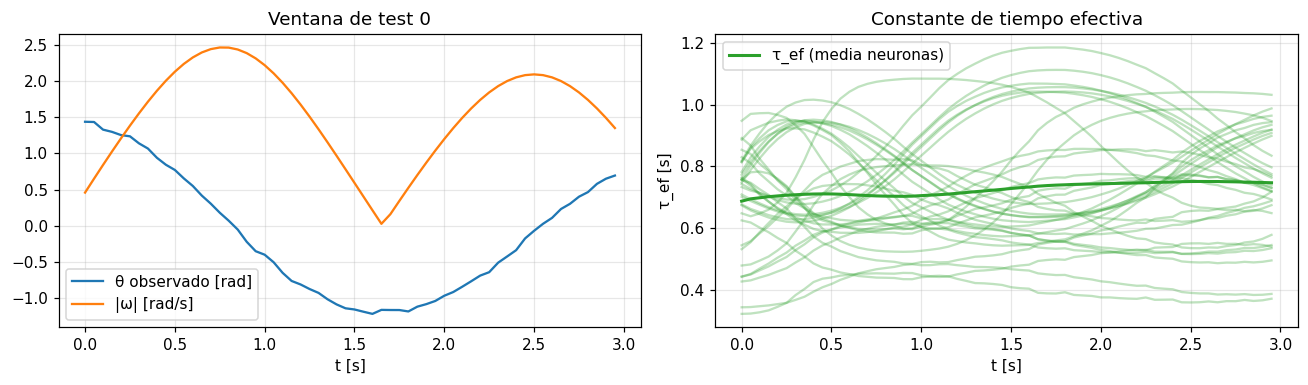

In [22]:
@torch.no_grad()
def tau_efectiva(modelo, X):
    """τ_ef(t) = 1/(1/τ + f(t)) por neurona, recorriendo la misma ODE que LiquidCell. X: (n,L,1) -> (n,L,N_h)"""
    capa = modelo.liquid_layer
    x = torch.from_numpy(X); B, T, _ = x.shape
    h = torch.zeros(B, capa.hidden_features)
    tau = torch.abs(capa.tau_raw) + 1e-3
    taus = []
    for t in range(T):
        f = torch.sigmoid(x[:, t, :] @ capa.w_in.t() + h @ capa.w_rec.t() + capa.bias)
        taus.append(1.0 / (1.0 / tau + f))
        h = h + capa.dt * (-((1.0 / tau) + f) * h + f * capa.A)
    return torch.stack(taus, dim=1).numpy()

P = PART["test"]; w = CONFIG.calentamiento
tau_ef = tau_efectiva(MODELOS[(N_LNN, SEM0)], P["X"])                  # (n, L, N_h)
tau_base = (np.abs(MODELOS[(N_LNN, SEM0)].liquid_layer.tau_raw.detach().numpy()) + 1e-3)
tau_prom = tau_ef.mean(axis=2)                                         # promedio sobre neuronas
vel = np.abs(P["omega"][:, :, 0])
r = np.corrcoef(tau_prom[:, w:].ravel(), vel[:, w:].ravel())[0, 1]
print(f"τ base (media sobre neuronas): {tau_base.mean():.3f} s | τ_ef: media {tau_ef[:, w:].mean():.3f} s, "
      f"rango [{tau_ef[:, w:].min():.3f}, {tau_ef[:, w:].max():.3f}] s")
print(f"Variación relativa de τ_ef en el tiempo (std/media, promedio de neuronas): {(tau_ef[:, w:].std(axis=1)/tau_ef[:, w:].mean(axis=1)).mean():.3f}")
print(f"Correlación (τ_ef promedio, |ω|) en test: r = {r:+.3f}")

j = 0; tt = np.arange(CONFIG.largo_ventana) * CONFIG.paso_muestreo
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(tt, P["X"][j, :, 0] * SD + MU, label="θ observado [rad]"); ax[0].plot(tt, vel[j], label="|ω| [rad/s]")
ax[0].set(title=f"Ventana de test {j}", xlabel="t [s]"); ax[0].legend()
ax[1].plot(tt, tau_ef[j], alpha=0.3, color="C2"); ax[1].plot(tt, tau_prom[j], color="C2", lw=2, label="τ_ef (media neuronas)")
ax[1].set(title="Constante de tiempo efectiva", xlabel="t [s]", ylabel="τ_ef [s]"); ax[1].legend()
plt.tight_layout(); plt.show()

**Lectura (4.7).** τ base media = 0.974 s; τ_ef media = 0.734 s, con rango [0.339, 1.209] s. La variación temporal relativa de τ_ef (desde el paso 19) es de solo 4.5 %, y su correlación con |ω| es r = −0.186: el signo coincide con la teoría (más velocidad, τ_ef menor), pero es débil. La red usa la modulación sobre todo como un desplazamiento casi constante de τ (de 0.97 a 0.73 s), no como adaptación dinámica, lo que es coherente con H1 no sostenida. En la figura algunas neuronas individuales sí cambian bastante, pero el promedio entre neuronas es casi plano.

### 4.8 Comparación con una implementación de biblioteca (`ncps`)

El orden de trabajo de la plantilla termina en *implementación mínima → biblioteca*. Hasta aquí la LNN es la implementación propia de §1 (Euler explícito de la ODE con conductancia sigmoide). Esta sección la compara con `ncps.torch.LTC` (paquete de los autores de las LTC, licencia Apache-2.0), con la **misma** partición, métrica, tubería de entrenamiento (`entrenar`), presupuesto de épocas y semillas. Diferencias que hay que tener presentes al leer el resultado:

- La biblioteca implementa el modelo biofísico original: conductancias sinápticas sigmoides con parámetros $\mu,\sigma$ entrenables, potenciales de reversión, conductancia de fuga y capacitancia de membrana, con sinapsis sensoriales (entrada) y recurrentes separadas. La implementación propia usa la forma simplificada de §1.1.
- Integra con un solucionador semi-implícito con 6 «desdoblamientos» por paso de la secuencia; la propia usa un paso de Euler explícito con $\Delta t=0.05$ s. En esta llamada la biblioteca no recibe $\Delta t$ (usa una unidad de tiempo por muestra), de modo que sus constantes de tiempo se aprenden en esas unidades.
- Tiene más parámetros por neurona, así que el número de unidades se elige automáticamente para que el total de parámetros quede lo más cerca posible del de la LNN propia (se imprime el conteo real).
- `ncps` no viene preinstalado en Colab: la celda lo instala con `pip` si falta.

In [23]:
# ---------- 4.8 LTC de biblioteca (ncps), misma tubería que el resto ----------
import subprocess, sys
try:
    from ncps.torch import LTC
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ncps"], check=True)
    from ncps.torch import LTC

class LTCBiblioteca(nn.Module):
    """ncps.torch.LTC + la misma cabeza lineal que la LNN propia. Interfaz (B,T,1) -> (B,T,1)."""
    def __init__(self, unidades, entrada=1, salida=1):
        super().__init__()
        self.ltc = LTC(entrada, unidades, return_sequences=True, batch_first=True,
                       input_mapping="affine", output_mapping="none")
        self.cabeza = nn.Linear(unidades, salida)
    def forward(self, x):
        h, _ = self.ltc(x)
        return self.cabeza(h)

# Unidades elegidas para igualar (lo más posible) el número de parámetros de la LNN propia
N_REF = contar_parametros(MODELOS[(N_LNN, CONFIG.semillas[0])])
UNIDADES_LIB = min(range(4, 33), key=lambda u: abs(contar_parametros(LTCBiblioteca(u)) - N_REF))
N_LIB = f"LTC biblioteca (ncps, {UNIDADES_LIB} unidades)"
FABRICAS[N_LIB] = lambda: LTCBiblioteca(UNIDADES_LIB)
SEMILLAS_LIB = CONFIG.semillas
print(f"{N_LIB}: {contar_parametros(LTCBiblioteca(UNIDADES_LIB))} parámetros (LNN propia: {N_REF}, GRU: {contar_parametros(FABRICAS[N_GRU]())})")

# Si el runtime se corta, volver a ejecutar: las corridas ya hechas se saltan.
for s in SEMILLAS_LIB:
    correr(N_LIB, s)

LTC biblioteca (ncps, 16 unidades): 1155 parámetros (LNN propia: 1185, GRU: 1153)
LTC biblioteca (ncps, 16 unidades) semilla 0:  836.0 s, mejor época 80, RMSE val = 0.0287 rad
LTC biblioteca (ncps, 16 unidades) semilla 1:  913.7 s, mejor época 95, RMSE val = 0.0242 rad
LTC biblioteca (ncps, 16 unidades) semilla 2:  904.2 s, mejor época 92, RMSE val = 0.0283 rad
LTC biblioteca (ncps, 16 unidades) semilla 3:  488.4 s, mejor época 43, RMSE val = 0.0480 rad
LTC biblioteca (ncps, 16 unidades) semilla 4:  616.7 s, mejor época 57, RMSE val = 0.0279 rad


In [24]:
# ---------- Resumen y veredicto automático (no abre el test otra vez) ----------
r_ = resultados.copy(); r_[COLS_NUM] = r_[COLS_NUM].astype(float)
g_ = r_.groupby("modelo", sort=False)[COLS_NUM]
m_lib, s_lib = g_.mean(), g_.std().fillna(0.0)

orden_lib = [N_LIB, N_LNN, N_TAUFIJA, N_GRU, N_MLP, N_RIDGE]
fmt_ = lambda m, c: f"{m_lib.loc[m, c]:.4f} ± {s_lib.loc[m, c]:.4f}"
display(pd.DataFrame({
    "parámetros": [int(m_lib.loc[m, "parámetros_entrenables"]) for m in orden_lib],
    "tiempo/entrenamiento [s]": [round(m_lib.loc[m, "tiempo_s"], 1) for m in orden_lib],
    "RMSE test [rad]": [fmt_(m, "métrica_test") for m in orden_lib],
    "RMSE OOD [rad]": [fmt_(m, "métrica_ood") for m in orden_lib],
    "OOD / test": [round(m_lib.loc[m, "métrica_ood"] / m_lib.loc[m, "métrica_test"], 2) for m in orden_lib],
}, index=orden_lib))

def veredicto_lib(ref, col):
    d = float(m_lib.loc[N_LIB, col] - m_lib.loc[ref, col])
    disp = max(float(np.hypot(s_lib.loc[N_LIB, col], s_lib.loc[ref, col])), 1e-12)
    return "MEJOR que" if d < -disp else ("PEOR que" if d > disp else "EMPATA (dentro de la dispersión) con")

for col, etiqueta in [("métrica_test", "test"), ("métrica_ood", "OOD")]:
    for ref in (N_LNN, N_GRU, N_MLP):
        print(f"RMSE {etiqueta}: la LTC de biblioteca {veredicto_lib(ref, col)} {ref}  "
              f"({m_lib.loc[N_LIB, col]:.4f} vs {m_lib.loc[ref, col]:.4f} rad)")
print(f"Tiempo de entrenamiento: biblioteca {m_lib.loc[N_LIB, 'tiempo_s']:.0f} s vs LNN propia {m_lib.loc[N_LNN, 'tiempo_s']:.0f} s "
      f"(×{m_lib.loc[N_LIB, 'tiempo_s'] / m_lib.loc[N_LNN, 'tiempo_s']:.1f})")

,parámetros,tiempo/entrenamiento [s],RMSE test [rad],RMSE OOD [rad],OOD / test
"LTC biblioteca (ncps, 16 unidades)",1155,751.8,0.0327 ± 0.0104,0.2166 ± 0.0292,6.63
"LNN (base, N_h=32)",1185,71.2,0.0174 ± 0.0005,0.0934 ± 0.0053,5.37
Abl. (a): τ fija,1185,63.1,0.0173 ± 0.0008,0.0821 ± 0.0032,4.73
GRU,1153,62.9,0.0086 ± 0.0006,0.1199 ± 0.0134,13.93
MLP (20 rezagos),5569,11.7,0.0127 ± 0.0007,0.1534 ± 0.0063,12.06
Ridge (20 rezagos),21,0.1,0.0270 ± 0.0000,0.1927 ± 0.0000,7.14


RMSE test: la LTC de biblioteca PEOR que LNN (base, N_h=32)  (0.0327 vs 0.0174 rad)
RMSE test: la LTC de biblioteca PEOR que GRU  (0.0327 vs 0.0086 rad)
RMSE test: la LTC de biblioteca PEOR que MLP (20 rezagos)  (0.0327 vs 0.0127 rad)
RMSE OOD: la LTC de biblioteca PEOR que LNN (base, N_h=32)  (0.2166 vs 0.0934 rad)
RMSE OOD: la LTC de biblioteca PEOR que GRU  (0.2166 vs 0.1199 rad)
RMSE OOD: la LTC de biblioteca PEOR que MLP (20 rezagos)  (0.2166 vs 0.1534 rad)
Tiempo de entrenamiento: biblioteca 752 s vs LNN propia 71 s (×10.6)


### 4.9 Lista de control y artefactos

Las casillas se calculan a partir de lo realmente ejecutado. `notebook_desde_cero` y `licencia_datos` son revisiones manuales: no se marcan solas. La celda guarda además `resultados.csv`, `config.json` y `requirements.txt` (versiones exactas de este runtime) para subirlos al repositorio.

In [26]:
LICENCIA_DATOS_REVISADA = True      # datos simulados con código propio (documentado en §2.2): confirmar en grupo
NOTEBOOK_DESDE_CERO = True         # poner True SOLO después de: Reiniciar runtime → Run all sin errores

n_sem = resultados.groupby("modelo").size()
lista_control = {
    "test_intacto": len(_TEST_ABIERTO) == len(resultados),
    "pipeline_sin_fuga": ESTADO["fuga_ok"],
    "línea_base": {N_PERSIST, N_MEDIA, N_RIDGE, N_MLP, N_GRU} <= set(resultados["modelo"]),
    "matemática_y_formas": ESTADO["formas_ok"],
    "ablaciones": all(n_sem.get(m, 0) == len(CONFIG.semillas) for m in (N_TAUFIJA, N_H8, N_H16)),
    "comparación_biblioteca": n_sem.get(N_LIB, 0) == len(SEMILLAS_LIB),
    "varias_semillas": len(CONFIG.semillas) >= 3 and n_sem.get(N_LNN, 0) == len(CONFIG.semillas),
    "licencia_datos": LICENCIA_DATOS_REVISADA,
    "notebook_desde_cero": NOTEBOOK_DESDE_CERO,
}
display(pd.Series(lista_control, name="completado"))
print("Elementos pendientes:", [k for k, v in lista_control.items() if not v])

# ---- Artefactos para el repositorio ----
import importlib.metadata as md_
resultados.to_csv("resultados.csv", index=False)
with open("config.json", "w") as f: json.dump(asdict(CONFIG), f, indent=2, ensure_ascii=False)
with open("requirements.txt", "w") as f:
    for lib in ["numpy", "pandas", "scipy", "scikit-learn", "torch", "matplotlib", "ncps"]:
        f.write(f"{lib}=={md_.version(lib).split('+')[0]}\n")
print("Python", platform.python_version())
print(open("requirements.txt").read())
print("Guardados: resultados.csv, config.json, requirements.txt (descargarlos desde el panel de archivos de Colab para el repositorio).")


,completado
test_intacto,True
pipeline_sin_fuga,True
línea_base,True
matemática_y_formas,True
ablaciones,True
comparación_biblioteca,True
varias_semillas,True
licencia_datos,True
notebook_desde_cero,True


Elementos pendientes: []
Python 3.13.18
numpy==2.4.6
pandas==2.2.3
scipy==1.16.3
scikit-learn==1.6.1
torch==2.14.1
matplotlib==3.10.0
ncps==1.0.1

Guardados: resultados.csv, config.json, requirements.txt (descargarlos desde el panel de archivos de Colab para el repositorio).


### 4.10 Interpretación física y conclusiones

*Cifras: media ± desviación estándar entre 5 semillas, tomadas de las tablas de §4.2, §4.2b, §4.5 y §4.7 de esta ejecución. Si se vuelve a entrenar con otra configuración, hay que actualizarlas.*

**La idea en una imagen.** Cada neurona líquida tiene una «memoria» de duración $\tau$: el tiempo que tarda en olvidar lo que sintió. En una LTC esa duración no es fija: se acorta o se alarga según lo que entra, $\tau_{ef}=1/(1/\tau+f)$. La apuesta era que un péndulo grande, cuya respuesta cambia con la amplitud (es anarmónico), se beneficiaría de esa flexibilidad. Lo que midieron los datos es más modesto, y por eso más interesante.

#### 1. H1 (la constante de tiempo líquida ayuda): no se sostiene
- **Líquida vs. $\tau$ fija** (definición de §2.1): RMSE de test 0.0174 ± 0.0005 rad frente a 0.0173 ± 0.0008 rad. La diferencia (−0.0001 rad) es mucho menor que la dispersión combinada (0.0010 rad). Con el mismo número de parámetros (1185), la «liquidez» no mejora nada dentro de la distribución de entrenamiento.
- **Comparación adicional con GRU y MLP** (no es H1): en test la GRU (0.0086 ± 0.0006 rad) tiene la mitad del error de la LNN y la MLP (0.0127 ± 0.0007 rad) también es mejor. La LNN solo supera a Ridge (0.0270 rad, ≈36 % menos error) y a las líneas base ingenuas (≈0.34 y 0.36 rad).
- **Lectura física:** en la LNN entrenada $\tau_{ef}$ casi no cambia en el tiempo (variación relativa 0.045) y su correlación con $|\omega|$ es débil ($r=-0.19$). La red se comporta casi como un sistema con constante de tiempo fija; la «liquidez» prácticamente no se usa, lo que concuerda con la ablación.

#### 2. H2 (degrada menos fuera de distribución): se sostiene, con salvedades
- **Cociente OOD/test:** LNN 5.37, MLP 12.06, GRU 13.93 (Ridge 7.14).
- **Error absoluto en OOD** (§4.2b): LNN 0.0934 ± 0.0053 rad frente a GRU 0.1199 ± 0.0134 (la LNN tiene 22 % menos error; la diferencia es ≈1.8 veces la dispersión combinada: evidencia moderada con 5 semillas), MLP 0.1534 ± 0.0063 (39 % menos) y Ridge 0.1927 (52 % menos). La ventaja no depende de que el error de test de la LNN sea más alto.
- **Salvedad:** la ventaja no se puede atribuir a la constante de tiempo líquida. La variante con $\tau$ fija generaliza aún mejor (0.0821 ± 0.0032 rad; cociente 4.73), con una diferencia de 0.011 rad, casi el doble de la dispersión combinada (0.0062 rad). Lo que parece ayudar es la estructura de ecuación diferencial con estado acotado y disipativo (§1.6; conjetura no verificada aquí), no que $\tau$ dependa del estado.

#### 3. Otros resultados
- **Capacidad:** al pasar de $N_h=8$ a 16 y 32, el RMSE de test baja de 0.0268 a 0.0199 y 0.0174 rad (la capa de 8 neuronas es 54 % peor que la base). En OOD, 0.1328 → 0.1120 → 0.0934 rad. La capacidad sigue ayudando hasta 32 neuronas.
- **Dónde falla:** las 3 peores ventanas de la LNN son OOD y arrancan cerca del punto de retorno ($\theta\approx 2.8$ rad, $\omega\approx 0$), donde la fuerza restauradora casi se anula; la red predice una caída más rápida que la real. Que esto se deba a extrapolar fuera de $|\theta|\le 1.8$ rad es una explicación probable, no comprobada.
- **Costo:** entrenar la LNN toma ≈66 s y ≈0.28 Wh frente a ≈57 s de la GRU y ≈10 s de la MLP; los entrenamientos de §3–§4.7 suman ≈25.8 min y ≈1.3 g CO₂e (con los supuestos de §4.4; la comparación de §4.8 no está incluida en esa cuenta). La inferencia es del mismo orden en todas las redes (≈0.02–0.03 ms por ventana).

#### 4. Comparación con una LTC de biblioteca
§4.8 compara la LNN propia con `ncps.LTC` bajo la misma partición, métrica, tubería, presupuesto de épocas y semillas, con un número de parámetros comparable. La celda imprime el veredicto de cada comparación (mejor, peor o empate dentro de la dispersión combinada) y la razón de tiempos de entrenamiento. Sirve para separar dos preguntas: si lo observado en este trabajo depende de la forma simplificada de la ODE de §1 o es propio de las LTC en general, y cuánto cambia el costo con una implementación de biblioteca (6 desdoblamientos del solucionador por paso). Las cifras están en la salida de §4.8.

#### 5. Límites de estas conclusiones
- **Entrenamiento truncado:** la LNN y sus variantes alcanzan su mejor época entre la 95 y la 99 de un máximo de 100 (la GRU llega a la 99), de modo que la parada temprana no se activó. Los resultados comparan modelos con el *mismo presupuesto de 100 épocas*, no con modelos convergidos; con más épocas la clasificación podría cambiar. Además, ese presupuesto se cambió una vez (de 60 a 100) tras una corrida exploratoria previa (ver §4.6).
- **Un solo sistema físico** (péndulo con $g/L$ y $\gamma$ fijos), ruido gaussiano, muestreo regular y datos simulados sin desajuste modelo-realidad.
- **Solo 5 semillas** y una única partición de datos: las desviaciones son estimaciones gruesas y no incluyen la variabilidad por partición.
- **Sin evaluar muestreo irregular**, que es donde la teoría de las LNN promete más ventaja, y **sin imponer la simetría** $\theta\to-\theta$ (§1.6).

#### 6. Síntesis y siguiente experimento
Para reconstruir y extrapolar un péndulo anarmónico desde un sensor ruidoso, la LNN base fue la mejor entre las redes comparadas fuera de distribución (salvo la variante de $\tau$ fija), pero no dentro de ella, donde la GRU gana claramente. Y el mérito no es de su $\tau$ dependiente del estado, que apenas varía y que no mejora nada al compararla con $\tau$ fija. Siguientes experimentos, en orden de informatividad: (i) muestreo irregular con $\Delta t$ por paso (la biblioteca admite `timespans`), comparando contra GRU y contra la versión con $\tau$ fija, que es donde sí se podría ver una diferencia atribuible a la liquidez; (ii) entrenar con más épocas (por ejemplo 300) hasta que se active la parada temprana, y con amplitudes mayores para comprobar la interpretación del fallo cerca del punto inestable; (iii) imponer la simetría $\theta\to-\theta$ y medir su efecto en OOD; (iv) un sistema más complejo (por ejemplo, Lorenz) y otras variantes de la biblioteca (CfC, o un cableado NCP).

## 5. Estructura sugerida de la sustentación

1. problema físico y datos;
2. fundamento matemático del método nuevo;
3. diseño experimental y línea base;
4. resultados, incertidumbre y ablaciones;
5. fallo más interesante;
6. conclusión y siguiente experimento.


### 5.1

1. **Problema físico y datos** *.* Péndulo amortiguado no lineal ($g/L=4$ s⁻², $\gamma=0.2$ s⁻¹), sensor que solo mide $\theta$ con ruido de 0.02 rad; hay que predecir $\theta$ medio segundo adelante. 300 trayectorias (partidas por trayectoria: 180/60/60) y 60 trayectorias OOD con amplitudes de 2.3 a 2.8 rad.
2. **Fundamento del método nuevo** *.* Ecuación de la LTC, discretización de Euler, regla de actualización (BPTT + Adam) y 1185 parámetros (fórmula de §1.4 verificada con PyTorch). Imagen: una memoria cuya duración puede cambiar con la entrada. Qué propiedades encajan con el péndulo (§1.6): sistema autónomo, estado acotado y disipativo; y cuál no se impone (simetría $\theta\to-\theta$).
3. **Diseño experimental y línea base** *.* Mismas particiones y métrica para todos; líneas base ingenuas, Ridge, MLP y GRU con tamaño comparable; test abierto una sola vez por modelo y semilla; 5 semillas; además una LTC de biblioteca (`ncps`) como contraste.
4. **Resultados, incertidumbre y ablaciones** *.* Test: GRU 0.0086, MLP 0.0127, LNN 0.0174, Ridge 0.0270 rad. OOD: τ fija 0.0821, LNN 0.0934, GRU 0.1199, MLP 0.1534, Ridge 0.1927 rad. Ablaciones: τ fija igual en test y mejor en OOD; $N_h=8$ es 54 % peor.
5. **Fallo más interesante** *.* Las peores ventanas OOD empiezan cerca del punto de retorno (θ≈2.8 rad) y la LNN predice una caída demasiado rápida. Además, $\tau_{ef}$ casi no varía (4.5 %), así que la «liquidez» no se usa: H1 se falsa.
6. **Conclusión y siguiente experimento** *.* H1 falsada; H2 se sostiene pero sin atribuirla a la liquidez; entrenar hasta la parada temprana (100 épocas fue el techo) y probar muestreo irregular.

Antes de entregar, reinicie el runtime y ejecute **Run all**. El notebook
final debe funcionar sin archivos privados ni rutas del computador del
estudiante. Las afirmaciones deben corresponder a las figuras y tablas
realmente obtenidas, no sólo a expectativas teóricas.
